# Case Study 01 — Personal-Loan Portfolio Health Check

**Descriptive statistics · distribution shape · sampling · Central Limit Theorem · confidence intervals · one-sample tests**

| | |
|---|---|
| **Domain** | Retail lending (unsecured personal loans) |
| **Stakeholder** | Chief Risk Officer (CRO), for the quarterly Board Risk Committee |
| **Difficulty** | Beginner |
| **Importance** | 🔴 MUST GO THROUGH |
| **Data** | Audited simple random sample of 2,500 loans from a book of 60,000 |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py` for exactly how it was produced.

**What you will learn**

1. How to check a data extract before trusting any number from it.
2. How to summarise money-type (skewed) data, and when the mean or the median is the right number to report.
3. How to explain standard deviation, percentiles and dispersion to a business owner.
4. What distribution shapes (normal, log-normal, left-skewed, discrete) look like in real lending data, and why
   they matter.
5. Why a sample tells us about a book of loans: sampling error and the **Central Limit Theorem**.
6. How to build and **correctly explain** confidence intervals for a mean, a median and a proportion.
7. How to test a KPI against a target (one-sample t-test, one-sample proportion test), and what Type I and
   Type II errors mean for the Board.

## Section 1 — Business context

You are a data scientist in the **Retail Risk Analytics** team of a mid-sized Indian lender. The personal-loan
book has about **60,000 active loans** disbursed between January 2024 and June 2025.

Last quarter the bank migrated to a new loan-management system. Some fields in the new system (income, ages,
interest rates, delinquency flags) have not yet been reconciled, so the Risk team does not trust a straight
system report. **Internal Audit therefore pulled a simple random sample of 2,500 loan files**, re-verified them
against source documents, and handed you the audited extract.

The **Chief Risk Officer** writes:

> *"The Board Risk Committee meets in three weeks. I need a clean, defensible picture of the personal-loan book:
> what a typical loan looks like, how spread out the book is, whether the average ticket size is in line with
> the ₹3.0 lakh we assumed in the business plan, and, most importantly, whether the 12-month 90+ DPD rate is
> within our 4% risk appetite. Please tell me how confident we can be in each number, because the Board will ask."*

Glossary for non-lending readers:

- **Ticket size**: the loan amount disbursed.
- **DPD (days past due)**: how many days a payment is overdue. **90+ DPD** is the industry's standard
  "serious delinquency / default" marker.
- **12-month 90+ DPD rate**: share of loans that became 90+ DPD at any point in their first 12 months on book.
  All sampled loans have at least 12 months on book, so the flag is fully observed.
- **DTI (debt-to-income)**: total monthly debt repayments ÷ monthly income. Policy caps DTI at 65%. Above that, a
  loan needs a documented **policy exception**, and the Board limits exceptions to 1% of the book.
- **Lakh** = 100,000. **Crore** = 10,000,000 (100 lakh).

## Section 2 — Business questions

In plain English, the CRO wants to know:

1. **Data trust:** Is the audit extract clean enough to report from? What had to be fixed?
2. **Typical loan:** What does a typical personal loan look like (amount, rate, tenure, borrower profile)?
3. **Spread and concentration:** How different are loans from each other? How concentrated is exposure in
   large loans?
4. **Ticket size vs plan:** Is the average ticket size in line with the ₹3.0 lakh plan assumption?
5. **Risk appetite:** Is the 12-month 90+ DPD rate within the 4% risk appetite?
6. **Policy exceptions:** Is the share of DTI policy exceptions within the 1% Board limit?
7. **Confidence:** How confident can we be in each number, given that it comes from a sample?

## Section 3 — Statistical translation

The single most important habit in this book: **translate every business question into a statistical one
before you touch a method.**

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Can we trust the extract? | Are there duplicates, missing values, impossible values, unit errors? | Data-quality checks, consistency rules |
| 2 | What does a typical loan look like? | What are the centre and shape of each variable's distribution? | Mean, median, mode, trimmed mean; histograms |
| 3 | How spread out / concentrated is the book? | What are the dispersion and tail behaviour? | SD, IQR, percentiles, CV, skewness, kurtosis; exposure concentration |
| 4 | Is average ticket size = ₹3.0 lakh? | Is the population mean loan amount μ different from 300,000? | 95% CI for μ; **one-sample t-test** (two-sided) |
| 5 | Is 90+ DPD rate within 4%? | Is the population proportion p greater than 0.04? | 95% CI for p (Wilson); **one-sample proportion test** (one-sided) |
| 6 | Are exceptions within 1%? | Is the proportion with DTI > 65% below 0.01? | 95% CI for a small proportion (Wilson vs Wald) |
| 7 | How confident are we? | What is the sampling error of each estimate? | Standard errors, CIs, CLT, coverage simulation |

Notice what is **not** on this list: *why* some loans default more than others. That is a question about
relationships and needs different tools (Case 02 onwards). This case is about **describing the book well
and quantifying uncertainty**.

### Setup

All paths are resolved relative to the repository, so the notebook runs from any folder. Shared helpers live in
`00_shared_resources/`. Each one is a few lines long, and we compute everything by hand first anyway.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportion_confint

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_pct, fmt_p, rng_for_case
from plotting import (set_style, save_fig, add_note, thousands_formatter,
                      COLORS, PRIMARY, HIGHLIGHT, INK, INK_MUTED)
from statistical_tests import describe_numeric, mean_ci, proportion_ci, bootstrap_ci

CASE_DIR = ROOT / "case_studies" / "01_loan_portfolio_health_check"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)
rng = rng_for_case(101)          # seeded generator for every simulation in this notebook

# Business parameters given by the CRO / policy documents
PLAN_AVG_TICKET = 300_000        # ₹, average ticket size assumed in the business plan
RISK_APPETITE_DPD90 = 0.04       # Board risk appetite: 12-month 90+ DPD rate
DTI_POLICY_CAP = 0.65            # loans above this DTI are policy exceptions
EXCEPTION_LIMIT = 0.01           # Board limit on the share of policy exceptions
BOOK_SIZE = 60_000               # loans in the book (known from the loan system)
LAKH = 100_000
lakh_fmt = thousands_formatter("₹", "L", LAKH, 1)

## Section 4 — Load the data

The audit extract is a CSV with one row per loan file reviewed.

In [2]:
raw = pd.read_csv(PATHS["data"] / "loan_audit_sample.csv")
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
raw.head()

Rows: 2,506   Columns: 15


,loan_id,disbursal_month,region,channel,employment_type,customer_age,monthly_income,credit_score,loan_amount,tenure_months,interest_rate,emi,existing_emi,dti,dpd90_12m
0,PL135060,2024-12,North,Branch,Self-employed,48.000,"33,900.000",766,120000,36,16.120,"4,226.000",0.000,0.125,0
1,PL154702,2025-05,North,Branch,Salaried,38.000,"45,600.000",734,150000,36,13.910,"5,120.000","1,900.000",0.154,0
2,PL146227,2025-03,North,Branch,Self-employed,35.000,"59,400.000",743,160000,12,17.140,"14,603.000",0.000,0.246,0
3,PL147523,2025-03,West,Branch,Salaried,30.000,"60,700.000",745,250000,24,17.220,"12,387.000","11,700.000",0.397,0
4,PL137877,2025-01,North,DSA,Salaried,38.000,"50,600.000",696,190000,48,13.030,"5,100.000","4,500.000",0.190,0


In [3]:
# A quick structural profile: type, completeness and cardinality of every column.
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "unique_values": raw.nunique(),
    "example": raw.iloc[0],
})
profile

,dtype,non_null,missing,unique_values,example
loan_id,str,2506,0,2500,PL135060
disbursal_month,str,2506,0,18,2024-12
region,str,2506,0,4,North
channel,str,2506,0,3,Branch
employment_type,str,2506,0,2,Self-employed
customer_age,float64,2506,0,43,48.000
monthly_income,float64,2416,90,1106,"33,900.000"
credit_score,int64,2506,0,267,766
loan_amount,int64,2506,0,121,120000
tenure_months,int64,2506,0,6,36


**Data dictionary**

| Column | Type | Meaning | Role here |
|---|---|---|---|
| `loan_id` | ID | Loan account number | Key; used for duplicate checks |
| `disbursal_month` | Date (YYYY-MM) | Month the loan was disbursed | Context / representativeness |
| `region`, `channel`, `employment_type` | Categorical | Where, how (Branch, Digital, DSA = direct selling agent) and to whom the loan was sold | Segments |
| `customer_age` | Numeric (years) | Age at disbursal (policy band 21–60) | Profile |
| `monthly_income` | Numeric (₹) | Verified monthly income | Profile |
| `credit_score` | Numeric (300–900) | Bureau score at application; **−1 means "no bureau history"** | Profile |
| `loan_amount` | Numeric (₹) | Disbursed amount (product range ₹50k–₹15 lakh) | **Target for Q2–Q4** |
| `tenure_months` | Discrete numeric | Loan term (12–60 months) | Profile |
| `interest_rate` | Numeric (% p.a.) | Contracted annual rate | Profile |
| `emi`, `existing_emi` | Numeric (₹) | This loan's monthly instalment; other monthly debt | Used to verify DTI |
| `dti` | Ratio | (emi + existing_emi) / monthly_income at origination | **Target for Q6** |
| `dpd90_12m` | Binary 0/1 | Ever 90+ DPD within first 12 months | **Target for Q5** |

There is no single "target" in this case. Each business question has its own outcome variable:
`loan_amount` (a continuous, money-type variable), `dpd90_12m` (a binary variable whose mean is a **proportion**)
and `dti > 0.65` (another proportion).

## Section 5 — Data quality

> Every number you report inherits the errors of the data underneath it. An analyst who skips this step will
> eventually present a wrong number to a Board, and lose credibility that takes years to rebuild.

We check, in order: **duplicates → missing values → impossible values → unit/consistency errors → outliers**.
For each problem we decide explicitly whether to **fix, flag, exclude or keep**, and we log the decision.

### 5.1 Duplicates

In [4]:
n_exact_dup = raw.duplicated().sum()
n_id_dup = raw["loan_id"].duplicated().sum()
print(f"Exact duplicate rows      : {n_exact_dup}")
print(f"Duplicated loan_id values : {n_id_dup}")

loans = raw.drop_duplicates().reset_index(drop=True)
assert loans["loan_id"].is_unique, "Same loan_id with different values: needs investigation, not dropping"
print(f"Rows after removing exact duplicates: {len(loans):,}")

Exact duplicate rows      : 6
Duplicated loan_id values : 6
Rows after removing exact duplicates: 2,500


**Why it matters:** a duplicated loan is counted twice in every average and every rate. Here the duplicates are
*exact* copies (every column identical), the typical symptom of a bad join in the extract, so dropping them is
safe. If the same `loan_id` had appeared with *different* values, we would **not** silently drop one. We would ask
the data owner which record is correct. The `assert` encodes that rule so it cannot be skipped.

### 5.2 Missing values

In [5]:
missing = pd.DataFrame({"missing": loans.isna().sum(), "pct_missing": loans.isna().mean()})
display(missing[missing["missing"] > 0])

# Is missingness related to anything? Compare by employment type.
(loans.assign(income_missing=loans["monthly_income"].isna())
      .groupby("employment_type")["income_missing"].agg(n_missing="sum", pct_missing="mean"))

,missing,pct_missing
monthly_income,90,0.036


,n_missing,pct_missing
employment_type,,
Salaried,32,0.018
Self-employed,58,0.084


Only `monthly_income` has missing values, and **not at random**: income is missing four to five times as often
for self-employed borrowers (their income is harder to re-verify) as for salaried ones. Two consequences:

- If we simply average the incomes we have, the average under-represents the self-employed. Self-employed
  incomes are more variable and on average a little higher, so the mean income would be slightly biased.
- We will **not impute** income here: no business question in this case depends on it. We report income
  statistics as "among loans with verified income" and flag the gap. Case 17 is devoted to missing-data
  mechanisms (MCAR / MAR / MNAR) and imputation.

### 5.3 Impossible and suspicious values

A value is suspicious if it breaks a **business rule** (a policy band, a product limit, a physical
impossibility), not merely if it is large.

In [6]:
rules = {
    "customer_age outside policy band 21-60": ~loans["customer_age"].between(21, 60),
    "interest_rate < 1 (looks like a decimal, not %)": loans["interest_rate"] < 1,
    "credit_score == -1 (bureau 'no hit' code)": loans["credit_score"].eq(-1),
    "credit_score outside 300-900 (excluding -1)": ~loans["credit_score"].between(300, 900) & loans["credit_score"].ne(-1),
    "loan_amount outside product range ₹50k-₹15L": ~loans["loan_amount"].between(50_000, 1_500_000),
    "tenure not in {12,18,24,36,48,60}": ~loans["tenure_months"].isin([12, 18, 24, 36, 48, 60]),
    "dti <= 0 or > 1": ~loans["dti"].between(0, 1, inclusive="right"),
    "dpd90_12m not 0/1": ~loans["dpd90_12m"].isin([0, 1]),
}
rule_results = pd.DataFrame({"rows_flagged": {k: int(v.sum()) for k, v in rules.items()}})
rule_results

,rows_flagged
customer_age outside policy band 21-60,3
"interest_rate < 1 (looks like a decimal, not %)",5
credit_score == -1 (bureau 'no hit' code),134
credit_score outside 300-900 (excluding -1),0
loan_amount outside product range ₹50k-₹15L,0
"tenure not in {12,18,24,36,48,60}",0
dti <= 0 or > 1,0
dpd90_12m not 0/1,0


In [7]:
print("Ages outside 21-60:", sorted(loans.loc[rules["customer_age outside policy band 21-60"], "customer_age"].tolist()))
loans.loc[rules["interest_rate < 1 (looks like a decimal, not %)"],
          ["loan_id", "loan_amount", "tenure_months", "interest_rate", "emi"]]

Ages outside 21-60: [3.0, 17.0, 230.0]


,loan_id,loan_amount,tenure_months,interest_rate,emi
90,PL104627,100000,48,0.153,"2,799.000"
1484,PL144808,750000,36,0.150,"25,992.000"
1744,PL152254,250000,36,0.143,"8,581.000"
1882,PL135391,210000,24,0.142,"10,106.000"
2463,PL152740,100000,60,0.165,"2,458.000"


- **Ages 3, 17 and 230** are typing errors (3 and 230 are impossible, 17 is below the minimum lending age). We
  cannot recover the true values, so we set them to missing. We do not impute them.
- **Interest rates like 0.155** are 15.5% keyed as a decimal. We can *prove* it: the stored EMI is consistent
  with 15.5% p.a., not 0.155% p.a. (verified below). This is an unambiguous unit error, so we correct it (×100).
- **Credit score −1** is not a score. It is the bureau's code for *no credit history* ("new to credit"). These are
  real customers with a meaningful status, so we keep the rows, set the score to missing, and create a flag
  `no_bureau_history`. Averaging −1 with scores of 750 would be a serious error, as shown in 5.5.

### 5.4 Consistency check: income vs DTI

`dti` was computed at origination from verified documents. If `monthly_income` is right, then
`(emi + existing_emi) / monthly_income` should reproduce `dti`.

In [8]:
implied_dti = (loans["emi"] + loans["existing_emi"]) / loans["monthly_income"]
dti_ratio = loans["dti"] / implied_dti
print(dti_ratio.describe(percentiles=[0.01, 0.5, 0.99]).round(3))
loans.loc[dti_ratio > 5, ["loan_id", "employment_type", "monthly_income", "emi", "existing_emi", "dti"]].assign(
    ratio=dti_ratio[dti_ratio > 5].round(2))

count   2,410.000
mean        1.018
std         0.448
min         0.999
1%          1.000
50%         1.000
99%         1.001
max        12.002
dtype: float64


,loan_id,employment_type,monthly_income,emi,existing_emi,dti,ratio
1113,PL144266,Salaried,"180,000.000","1,664.000",0.000,0.111,12.000
1777,PL113336,Salaried,"750,000.000","17,889.000",0.000,0.286,12.000
1983,PL138293,Salaried,"880,800.000","10,807.000","6,600.000",0.237,12.000
2398,PL134703,Salaried,"466,800.000","7,325.000",0.000,0.188,12.000


In [9]:
# Verify the interest-rate unit error using the EMI (annuity) formula.
def annuity_emi(principal, annual_rate_pct, months):
    r = annual_rate_pct / 1200
    return principal * r / (1 - (1 + r) ** (-months))

suspect = loans[loans["interest_rate"] < 1]
pd.DataFrame({
    "stored_emi": suspect["emi"],
    "emi_if_rate_as_stored": annuity_emi(suspect["loan_amount"], suspect["interest_rate"], suspect["tenure_months"]).round(),
    "emi_if_rate_x100": annuity_emi(suspect["loan_amount"], suspect["interest_rate"] * 100, suspect["tenure_months"]).round(),
})

,stored_emi,emi_if_rate_as_stored,emi_if_rate_x100
90,"2,799.000","2,090.000","2,799.000"
1484,"25,992.000","20,881.000","25,992.000"
1744,"8,581.000","6,960.000","8,581.000"
1882,"10,106.000","8,763.000","10,106.000"
2463,"2,458.000","1,674.000","2,458.000"


For 99% of loans the ratio is 1.00: income and DTI agree. For four loans it is almost exactly **12**. Their
income was keyed as *annual* instead of monthly. Because the ratio is exactly 12 (not a random
discrepancy), we correct these incomes (÷12) and log the fix. The EMI check confirms the interest-rate
correction: the stored EMI matches the ×100 rate.

### 5.5 Apply the cleaning decisions (and log them)

In [10]:
clean = loans.copy()
cleaning_log = []

bad_age = ~clean["customer_age"].between(21, 60)
clean.loc[bad_age, "customer_age"] = np.nan
cleaning_log.append(("customer_age", "Outside policy band 21-60 (typos: 3, 17, 230)", int(bad_age.sum()),
                     "Set to missing; reported to data owner; not imputed"))

rate_unit = clean["interest_rate"] < 1
clean.loc[rate_unit, "interest_rate"] *= 100
cleaning_log.append(("interest_rate", "Keyed as decimal (0.155 = 15.5%), confirmed via EMI", int(rate_unit.sum()),
                     "Corrected (x100)"))

annual_income = (dti_ratio > 5).fillna(False)
clean.loc[annual_income, "monthly_income"] /= 12
cleaning_log.append(("monthly_income", "Annual income keyed as monthly (DTI ratio = 12)", int(annual_income.sum()),
                     "Corrected (/12)"))

no_hit = clean["credit_score"].eq(-1)
clean["no_bureau_history"] = no_hit
clean.loc[no_hit, "credit_score"] = np.nan
cleaning_log.append(("credit_score", "-1 = no bureau history (a status, not a score)", int(no_hit.sum()),
                     "Score set to missing; flag no_bureau_history created; rows kept"))

cleaning_log.append(("monthly_income", "Missing (not re-verified; more often self-employed)",
                     int(clean["monthly_income"].isna().sum()), "Left missing; income stats reported on verified subset"))
cleaning_log.append(("(all)", "Exact duplicate rows", int(n_exact_dup), "Dropped"))

cleaning_log = pd.DataFrame(cleaning_log, columns=["column", "issue", "rows", "decision"])
save_table(cleaning_log, "data_cleaning_log", PATHS["tables"], index=False)
cleaning_log

,column,issue,rows,decision
0,customer_age,"Outside policy band 21-60 (typos: 3, 17, 230)",3,Set to missing; reported to data owner; not im...
1,interest_rate,"Keyed as decimal (0.155 = 15.5%), confirmed vi...",5,Corrected (x100)
2,monthly_income,Annual income keyed as monthly (DTI ratio = 12),4,Corrected (/12)
3,credit_score,"-1 = no bureau history (a status, not a score)",134,Score set to missing; flag no_bureau_history c...
4,monthly_income,Missing (not re-verified; more often self-empl...,90,Left missing; income stats reported on verifie...
5,(all),Exact duplicate rows,6,Dropped


In [11]:
# What would have happened if we had NOT cleaned? (sensitivity of headline numbers)
impact = pd.DataFrame({
    "uncleaned": [loans["credit_score"].mean(), loans["interest_rate"].mean(),
                  loans["monthly_income"].mean(), loans["monthly_income"].max(), loans["customer_age"].mean()],
    "cleaned": [clean["credit_score"].mean(), clean["interest_rate"].mean(),
                clean["monthly_income"].mean(), clean["monthly_income"].max(), clean["customer_age"].mean()],
}, index=["mean credit score", "mean interest rate (%)", "mean monthly income (₹)",
          "max monthly income (₹)", "mean age (years)"])
impact["change"] = impact["cleaned"] - impact["uncleaned"]
impact

,uncleaned,cleaned,change
mean credit score,715.921,756.525,40.603
mean interest rate (%),15.716,15.746,0.030
mean monthly income (₹),"73,427.925","72,561.618",-866.307
max monthly income (₹),"880,800.000","542,500.000","-338,300.000"
mean age (years),35.098,35.040,-0.058


**Lesson:** the −1 codes alone pull the average credit score down by about **40 points** (716 vs 757), a
difference large enough to change how the Board views portfolio quality. The five decimal-keyed rates shift the
average rate only slightly, and the four annual-income entries move the mean income by about 1%. But they create
a maximum "monthly income" of ₹8.8 lakh instead of ₹5.4 lakh, distorting any maximum, range or standard deviation. **The mean, SD and range are sensitive to bad values; the median and
percentiles much less so.** This is a recurring theme.

### 5.6 Outliers: look before you delete

The largest loans are around ₹15 lakh, five or six times the median. Are they errors?

In [12]:
amt = clean["loan_amount"]
q1, q3 = amt.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
big = clean[amt > upper_fence]
print(f"IQR rule upper fence: {fmt_money(upper_fence)}  ->  {len(big)} loans ({len(big) / len(clean):.1%}) flagged")
print(f"Largest loan: {fmt_money(amt.max())} (product cap is ₹15,00,000)")
big[["monthly_income", "loan_amount", "dti", "credit_score"]].describe().loc[["mean", "50%", "min", "max"]]

IQR rule upper fence: ₹775,000  ->  176 loans (7.0%) flagged
Largest loan: ₹1,500,000 (product cap is ₹15,00,000)


,monthly_income,loan_amount,dti,credit_score
mean,"167,347.059","1,087,556.818",0.354,746.578
50%,"144,650.000","1,030,000.000",0.343,744.000
min,"46,000.000","780,000.000",0.078,323.000
max,"542,500.000","1,500,000.000",0.756,873.000


The IQR rule flags 176 loans (7%) as "outliers". But these loans are **within the product limit**, belong
to customers with high verified incomes, and have normal DTIs and credit scores. They are **legitimate large
loans**, and they are exactly the loans that drive exposure. Deleting them would understate the book's size and
risk.

> **An outlier is not automatically bad data.** A statistical rule (IQR, z-score) only says a value is *unusual*.
> Whether it is an *error* is a business question. Case 16 is devoted to this.

Our analysis dataset is now `clean`: 2,500 audited loans.

## Section 6 — Descriptive statistics

### 6.1 Where is the "centre"? Mean, median, mode, trimmed mean

In [13]:
centre = pd.Series({
    "mean": amt.mean(),
    "median": amt.median(),
    "mode (most frequent value)": amt.mode().iloc[0],
    "5% trimmed mean": stats.trim_mean(amt, 0.05),
    "geometric mean": stats.gmean(amt),
}, name="loan_amount (₹)")
display(centre.to_frame().style.format("₹{:,.0f}"))
print("Five most common loan amounts:")
print(amt.value_counts().head(5).rename("loans").to_string())

,loan_amount (₹)
mean,"₹324,580"
median,"₹250,000"
mode (most frequent value),"₹150,000"
5% trimmed mean,"₹291,689"
geometric mean,"₹243,805"


Five most common loan amounts:
loan_amount
150000    169
100000    152
200000    136
250000    113
300000    100


Four "averages", four different answers. That is normal for money data. The question is which one fits the
*business question*.

| Statistic | What it answers | Use it when… |
|---|---|---|
| **Mean** | "If total exposure were spread equally, how much per loan?" Mean × number of loans = **total book**. | You care about **totals**: exposure, capital, revenue, provisioning. That is why the plan uses it. |
| **Median** | "What does the loan in the middle look like?" Half of loans are below, half above. | You describe the **typical customer**: product design, marketing, affordability. |
| **Mode** | "What is the single most common amount?" | Data is discrete or customers pick round numbers (here ₹1.5 lakh). Useful for product menus, rarely as a summary. |
| **Trimmed mean** | Mean after discarding the top and bottom 5% | You want a mean that is robust to extreme values. |
| **Geometric mean** | Typical value on a multiplicative scale | Log-normal-like data. Close to the median here. |

**Why the mean is above the median:** a few large loans (up to ₹15 lakh) pull the mean up. The median does not
move when the largest loan doubles; the mean does. When mean > median, the distribution is
**right-skewed**.

### 6.2 How spread out is the book? Dispersion

In [14]:
num_cols = ["loan_amount", "monthly_income", "interest_rate", "credit_score", "dti", "tenure_months", "customer_age"]
desc = pd.DataFrame({c: describe_numeric(clean[c]) for c in num_cols}).T
save_table(desc, "descriptive_statistics", PATHS["tables"])
desc[["n", "missing", "mean", "median", "std", "min", "p5", "p25", "p75", "p95", "max", "iqr", "cv",
      "skewness", "excess_kurtosis"]]

,n,missing,mean,median,std,min,p5,p25,p75,p95,max,iqr,cv,skewness,excess_kurtosis
loan_amount,"2,500.000",0.000,"324,580.000","250,000.000","270,745.461","50,000.000","60,000.000","150,000.000","400,000.000","900,000.000","1,500,000.000","250,000.000",0.834,2.039,4.871
monthly_income,"2,410.000",90.000,"72,561.618","60,150.000","49,353.172","15,000.000","22,700.000","40,600.000","89,700.000","165,755.000","542,500.000","49,100.000",0.680,2.431,10.211
interest_rate,"2,500.000",0.000,15.746,15.670,1.560,10.500,13.210,14.650,16.790,18.360,21.860,2.140,0.099,0.167,0.019
credit_score,"2,366.000",134.000,756.525,760.000,58.601,323.000,663.000,715.000,801.000,846.000,887.000,86.000,0.077,-0.565,1.950
dti,"2,500.000",0.000,0.297,0.283,0.142,0.033,0.093,0.186,0.394,0.558,0.756,0.208,0.478,0.449,-0.415
tenure_months,"2,500.000",0.000,35.448,36.000,13.601,12.000,12.000,24.000,48.000,60.000,60.000,24.000,0.384,0.219,-0.706
customer_age,"2,497.000",3.000,35.040,35.000,7.598,21.000,21.000,30.000,40.000,47.000,60.000,10.000,0.217,0.133,-0.257


How to read the dispersion statistics, and how to explain them to a business owner:

- **Variance** is the average squared distance from the mean. Its unit is "rupees squared", which nobody can
  interpret. We compute it because the SD and most tests are built from it.
- **Standard deviation (SD)** is the square root of the variance, back in rupees. For loan amount the SD is about
  **₹2.7 lakh**, almost as large as the mean (₹3.2 lakh). In business language: *"loan sizes vary a lot.
  Being ₹2–3 lakh away from the average is completely ordinary."* Caution: for skewed data the SD mixes a short
  left tail with a long right tail, so it is a poor description of "typical" spread.
- **Range** (max − min) uses only the two most extreme loans, so one unusual loan changes it.
- **Percentiles / IQR**: the middle 50% of loans lie between the 25th and 75th percentiles, ₹1.5 lakh to
  ₹4.0 lakh (IQR = ₹2.5 lakh). The 5th–95th percentile range (₹0.6–₹9.0 lakh) is what "nearly all loans" look
  like. Percentiles are robust and easy for executives to understand.
- **Coefficient of variation (CV = SD / mean)** compares spread across variables with different units. Loan
  amount has CV ≈ 0.83 (very heterogeneous). Interest rate has CV ≈ 0.10 (pricing is tightly clustered around
  15.7%). Using a CV, we can say "loan size varies about eight times more, relative to its average, than
  interest rate does".

**Why dispersion matters to the business:** two books with the same average ticket can carry very different
risk. A book where many loans are far above average concentrates exposure in fewer customers, so a handful of
defaults costs more. Averages alone hide this.

### 6.3 Shape: skewness and kurtosis

In [15]:
shape = desc[["skewness", "excess_kurtosis"]].copy()
shape["reading"] = np.select(
    [shape["skewness"] > 1, shape["skewness"] > 0.5, shape["skewness"] < -1, shape["skewness"] < -0.5],
    ["strongly right-skewed", "moderately right-skewed", "strongly left-skewed", "moderately left-skewed"],
    default="roughly symmetric")
shape

,skewness,excess_kurtosis,reading
loan_amount,2.039,4.871,strongly right-skewed
monthly_income,2.431,10.211,strongly right-skewed
interest_rate,0.167,0.019,roughly symmetric
credit_score,-0.565,1.950,moderately left-skewed
dti,0.449,-0.415,roughly symmetric
tenure_months,0.219,-0.706,roughly symmetric
customer_age,0.133,-0.257,roughly symmetric


- **Skewness** measures asymmetry. 0 = symmetric; positive = long right tail (a few very large values);
  negative = long left tail. As a rough guide, |skew| > 1 is strong.
  - `loan_amount` (skew ≈ 2.0) and `monthly_income` (≈ 2.4) are **strongly right-skewed**, as money variables
    almost always are: they cannot go below a floor but can be very large. `dti` is only mildly right-skewed
    (≈ 0.45) because the approval policy caps it.
  - `credit_score` is **moderately left-skewed** (≈ −0.57): approved customers cluster at high scores (≈ 760–820), with a tail of
    weaker customers. The approval policy cut off the very low scores, so the tail stops around 650 (plus a few
    policy exceptions).
  - `interest_rate` and `customer_age` are **roughly symmetric**.
- **Excess kurtosis** measures how heavy the tails are compared with a normal distribution (0 = normal).
  Loan amount and income have large positive kurtosis: extreme values are much more common than a
  normal distribution would predict. In risk work, heavy tails matter more than the average does.

### 6.4 Five-number summary and exposure concentration

In [16]:
five_num = amt.quantile([0, 0.25, 0.5, 0.75, 1.0])
five_num.index = ["minimum", "Q1 (25th pct)", "median", "Q3 (75th pct)", "maximum"]
display(five_num.map(fmt_money).to_frame("loan_amount"))

bands = pd.cut(amt, [0, 1e5, 2e5, 3e5, 5e5, 1e6, 1.5e6],
               labels=["≤ ₹1L", "₹1–2L", "₹2–3L", "₹3–5L", "₹5–10L", "₹10–15L"])
conc = clean.groupby(bands, observed=True).agg(loans=("loan_amount", "size"), exposure=("loan_amount", "sum"))
conc["share_of_loans"] = conc["loans"] / conc["loans"].sum()
conc["share_of_exposure"] = conc["exposure"] / conc["exposure"].sum()
top10_share = amt.sort_values(ascending=False).head(int(len(amt) * 0.10)).sum() / amt.sum()
save_table(conc, "exposure_concentration", PATHS["tables"])
print(f"The largest 10% of loans account for {top10_share:.1%} of total exposure.")
conc

,loan_amount
minimum,"₹50,000"
Q1 (25th pct),"₹150,000"
median,"₹250,000"
Q3 (75th pct),"₹400,000"
maximum,"₹1,500,000"


The largest 10% of loans account for 30.1% of total exposure.


,loans,exposure,share_of_loans,share_of_exposure
loan_amount,,,,
≤ ₹1L,379,29710000,0.152,0.037
₹1–2L,702,112520000,0.281,0.139
₹2–3L,477,123400000,0.191,0.152
₹3–5L,544,216630000,0.218,0.267
₹5–10L,306,212110000,0.122,0.261
₹10–15L,92,117080000,0.037,0.144


Loans of ₹5 lakh and above are about **one in six loans (16%) but 40% of the money**, and the largest 10% of
loans carry 30% of exposure. This is the practical meaning of right skew: **the customers who matter most for
losses are not the "typical" customers.** Risk monitoring should not rely on averages alone.

### 6.5 Categorical variables and group-wise descriptive statistics

In [17]:
for col in ["tenure_months", "channel", "employment_type"]:
    share = clean[col].value_counts(normalize=True).sort_index()
    print(f"{col}: " + ", ".join(f"{k} {v:.0%}" for k, v in share.items()) + f"   (mode: {clean[col].mode().iloc[0]})")
print(f"no bureau history: {clean['no_bureau_history'].mean():.1%} of loans")

tenure_months: 12 7%, 18 7%, 24 22%, 36 36%, 48 17%, 60 12%   (mode: 36)
channel: Branch 46%, DSA 19%, Digital 35%   (mode: Branch)
employment_type: Salaried 73%, Self-employed 27%   (mode: Salaried)
no bureau history: 5.4% of loans


In [18]:
def segment_summary(df, by):
    # Descriptive summary of a segment, including a Wilson CI for its 90+ DPD rate.
    out = df.groupby(by, observed=True).agg(
        loans=("loan_id", "size"),
        mean_amount=("loan_amount", "mean"),
        median_amount=("loan_amount", "median"),
        mean_rate=("interest_rate", "mean"),
        defaults=("dpd90_12m", "sum"),
    )
    out["share_of_loans"] = out["loans"] / out["loans"].sum()
    out["dpd90_rate"] = out["defaults"] / out["loans"]
    cis = [proportion_ci(k, n) for k, n in zip(out["defaults"], out["loans"])]
    out["dpd90_ci_low"] = [c["lower"] for c in cis]
    out["dpd90_ci_high"] = [c["upper"] for c in cis]
    return out

seg = pd.concat({"channel": segment_summary(clean, "channel"),
                 "employment_type": segment_summary(clean, "employment_type")})
save_table(seg, "segment_summary", PATHS["tables"])
seg

loans  mean_amount  median_amount  mean_rate  \
channel         Branch          1160  329,258.621    250,000.000     15.605   
                DSA              474  330,548.523    250,000.000     16.464   
                Digital          866  315,046.189    230,000.000     15.541   
employment_type Salaried        1813  310,744.622    250,000.000     15.556   
                Self-employed    687  361,091.703    250,000.000     16.245   

                               defaults  share_of_loans  dpd90_rate  \
channel         Branch               54           0.464       0.047   
                DSA                  40           0.190       0.084   
                Digital              40           0.346       0.046   
employment_type Salaried             90           0.725       0.050   
                Self-employed        44           0.275       0.064   

                               dpd90_ci_low  dpd90_ci_high  
channel         Branch                0.036          0.060  
                DSA                   0.063          0.113  
                Digital               0.034          0.062  
employment_type Salaried              0.041          0.061  
                Self-employed         0.048          0.085

Group-wise statistics are where business insight starts, and where over-interpretation starts too.

- **DSA-sourced loans** show a 90+ DPD rate of about 8.4%, against about 4.6–4.7% for Branch and Digital.
  **Self-employed** borrowers show 6.4% vs 5.0% for salaried. About 5% of customers have no bureau history.
- The DSA confidence interval (≈ 6.3%–11.3%) does not overlap with Branch's (3.6%–6.0%), a hint that the gap is real. The
  self-employed and salaried intervals overlap heavily.
- **Caution:** this section is *descriptive*. We have not tested whether these differences are larger than
  sampling noise, and we have not checked whether they are explained by something else (DSA customers may differ
  in credit score or DTI). Comparing groups properly is the subject of **Case 02**; untangling *why* is Cases 07,
  08 and 26.
- Also note: whether two confidence intervals overlap is **not** a valid significance test. Two intervals can
  overlap slightly while the difference is still statistically significant. Case 02 shows the right way.

## Section 7 — Visualisation

Numbers summarise; pictures show what the summary hides. Every figure below is followed by the four
questions a senior analyst asks: **what do we see, what does it mean statistically, why does the business care,
and what must we not conclude?**

### Figure 1 — The loan amount distribution

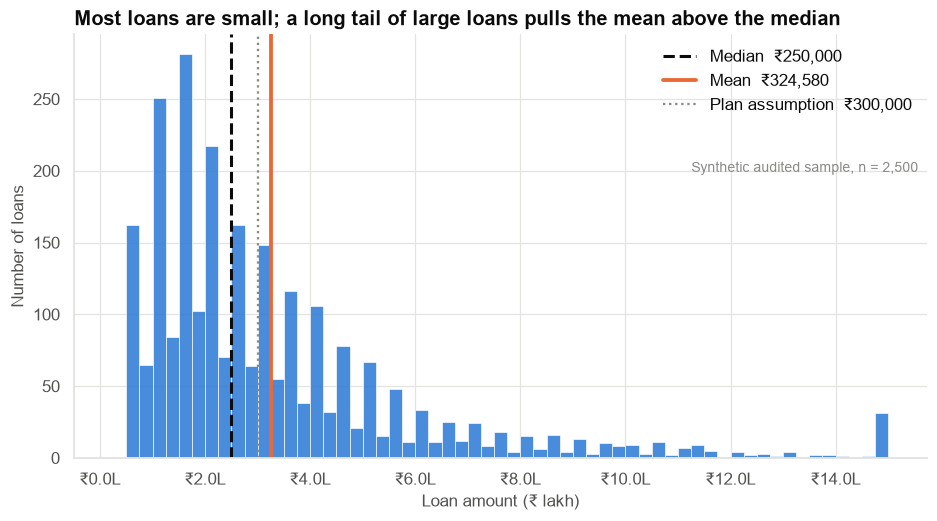

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(amt, bins=np.arange(25_000, 1_525_000, 25_000), color=PRIMARY, alpha=0.85, edgecolor="white", linewidth=0.5)
ax.axvline(amt.median(), color=INK, lw=2, ls="--", label=f"Median  {fmt_money(amt.median())}")
ax.axvline(amt.mean(), color=HIGHLIGHT, lw=2.5, label=f"Mean  {fmt_money(amt.mean())}")
ax.axvline(PLAN_AVG_TICKET, color=INK_MUTED, lw=1.5, ls=":", label=f"Plan assumption  {fmt_money(PLAN_AVG_TICKET)}")
ax.xaxis.set_major_formatter(lakh_fmt)
ax.set(title="Most loans are small; a long tail of large loans pulls the mean above the median",
       xlabel="Loan amount (₹ lakh)", ylabel="Number of loans")
ax.legend(loc="upper right")
add_note(ax, "Synthetic audited sample, n = 2,500", (0.99, 0.70, "right", "top"))
save_fig(fig, "fig01_loan_amount_distribution", PATHS["figures"])
plt.show()

**Observation.** Most loans are between ₹1 and ₹4 lakh. The distribution has a long right tail up to the
₹15 lakh cap, and there are sharp spikes at round amounts (₹1, 1.5, 2, 2.5, 3 lakh…).

**Interpretation.** The distribution is strongly right-skewed (skewness ≈ 2.0), so the mean (₹3.25 lakh) sits
well above the median (₹2.5 lakh). The spikes are **heaping**: customers ask for round numbers. It is a feature of
human behaviour, not a data error, but it means loan amount is not truly continuous.

**Business implication.** "Our average loan is ₹3.25 lakh" is correct for exposure planning, but it describes a
loan that is *larger than what most customers borrow*. If the product team designs offers around "the
average customer", they will design for the wrong person. Use the median (₹2.5 lakh) for that.

**Caveat.** The picture does not tell us whether larger loans are riskier, or whether the shape is changing over
time. It is one snapshot of a sample.

### Figure 2 — Different variables, different shapes

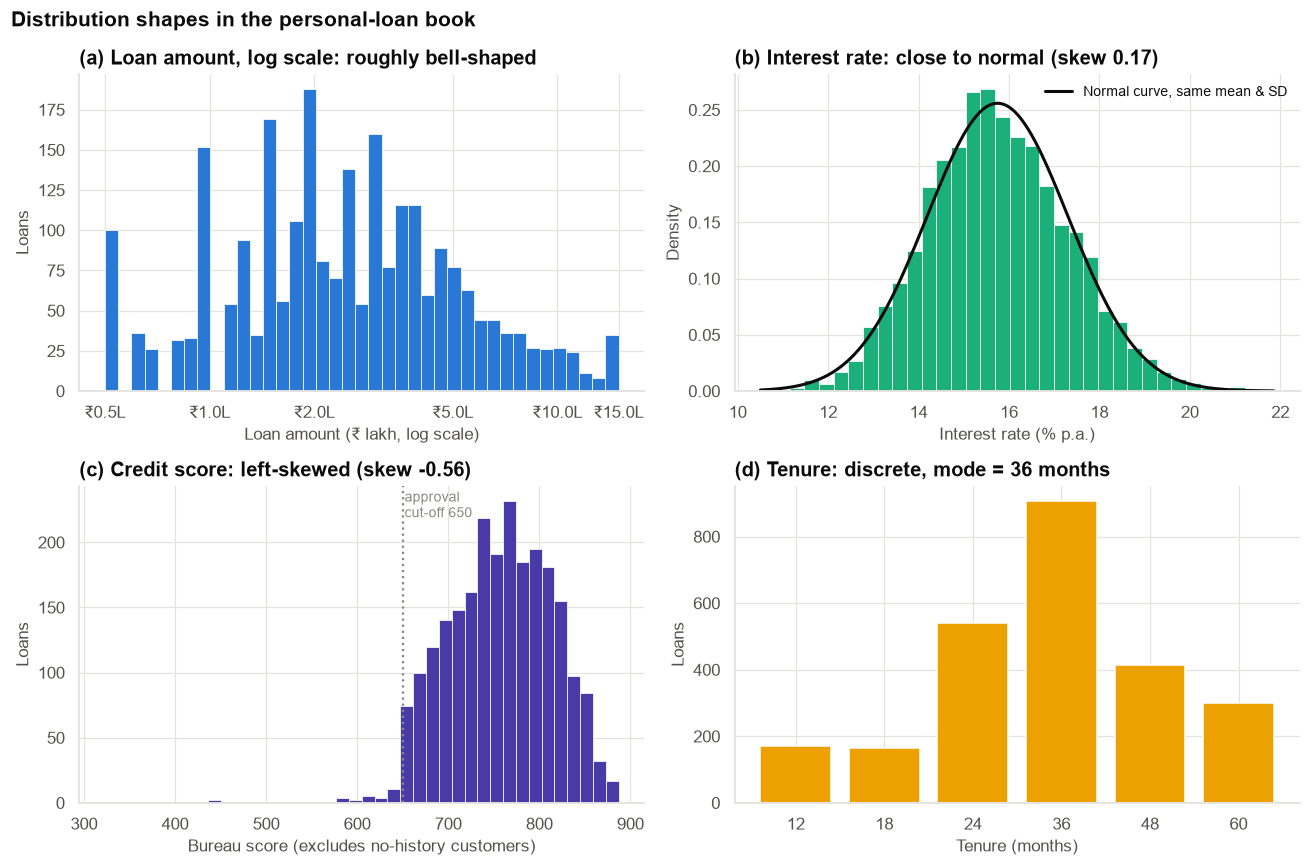

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# (a) loan amount on a log scale
ax = axes[0, 0]
log_bins = np.logspace(np.log10(50_000), np.log10(1_500_000), 40)
ax.hist(amt, bins=log_bins, color=PRIMARY, edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lakh_fmt)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks([50_000, 100_000, 200_000, 500_000, 1_000_000, 1_500_000])
ax.set(title="(a) Loan amount, log scale: roughly bell-shaped", xlabel="Loan amount (₹ lakh, log scale)", ylabel="Loans")

# (b) interest rate with a fitted normal curve
ax = axes[0, 1]
rate = clean["interest_rate"]
ax.hist(rate, bins=35, density=True, color=COLORS["aqua"], edgecolor="white", linewidth=0.5)
xs = np.linspace(rate.min(), rate.max(), 300)
ax.plot(xs, stats.norm.pdf(xs, rate.mean(), rate.std()), color=INK, lw=2, label="Normal curve, same mean & SD")
ax.set(title=f"(b) Interest rate: close to normal (skew {stats.skew(rate):.2f})", xlabel="Interest rate (% p.a.)", ylabel="Density")
ax.legend(loc="upper right", fontsize=9)

# (c) credit score: left-skewed and truncated by policy
ax = axes[1, 0]
ax.hist(clean["credit_score"].dropna(), bins=40, color=COLORS["violet"], edgecolor="white", linewidth=0.5)
ax.axvline(650, color=INK_MUTED, ls=":", lw=1.5)
ax.text(652, ax.get_ylim()[1] * 0.9, "approval\ncut-off 650", fontsize=9, color=INK_MUTED)
ax.set(title=f"(c) Credit score: left-skewed (skew {stats.skew(clean['credit_score'].dropna()):.2f})",
       xlabel="Bureau score (excludes no-history customers)", ylabel="Loans")

# (d) tenure: a discrete variable
ax = axes[1, 1]
ten = clean["tenure_months"].value_counts().sort_index()
ax.bar(ten.index.astype(str), ten.values, color=COLORS["yellow"], edgecolor="white")
ax.set(title="(d) Tenure: discrete, mode = 36 months", xlabel="Tenure (months)", ylabel="Loans")

fig.suptitle("Distribution shapes in the personal-loan book", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig02_distribution_shapes", PATHS["figures"])
plt.show()

**Observation.** (a) On a log scale the loan amount looks roughly bell-shaped. (b) Interest rates form a
near-symmetric bell around 15.7%. (c) Credit scores pile up at the high end with a tail to the left, cut off near
650. (d) Tenure takes only six values.

**Interpretation: what kind of business process produces each shape?**

| Shape | Typical business mechanism | Here |
|---|---|---|
| **Log-normal** (right-skewed, bell-shaped on log scale) | Quantities formed by *multiplying* many factors (income × leverage × appetite), bounded below by zero | Loan amount, income |
| **Normal** | A quantity formed by *adding* many small, independent influences around a set point | Interest rate = base rate + risk adjustments + negotiation noise |
| **Left-skewed and truncated** | A *selection* process that removes one tail | Approval policy removes low scores |
| **Discrete** | A menu of options | Tenure options 12–60 months |

**Business implication.** The shape decides which summary is honest. For interest rate, "15.7% ± 1.6 points" is a fair
description. For loan amount, "mean ± SD" would suggest negative loan amounts are possible (3.2 − 2 × 2.7 < 0),
which is a sign the SD is the wrong tool for that variable. Report percentiles instead.

**Caveat.** "Looks normal" is a judgement, not a fact. The Q-Q plot below is a better check. Also, none of
these shapes needs to be normal for this case's inference to work, as Section 9 explains.

### Figure 3 — Q-Q plots: checking normality properly

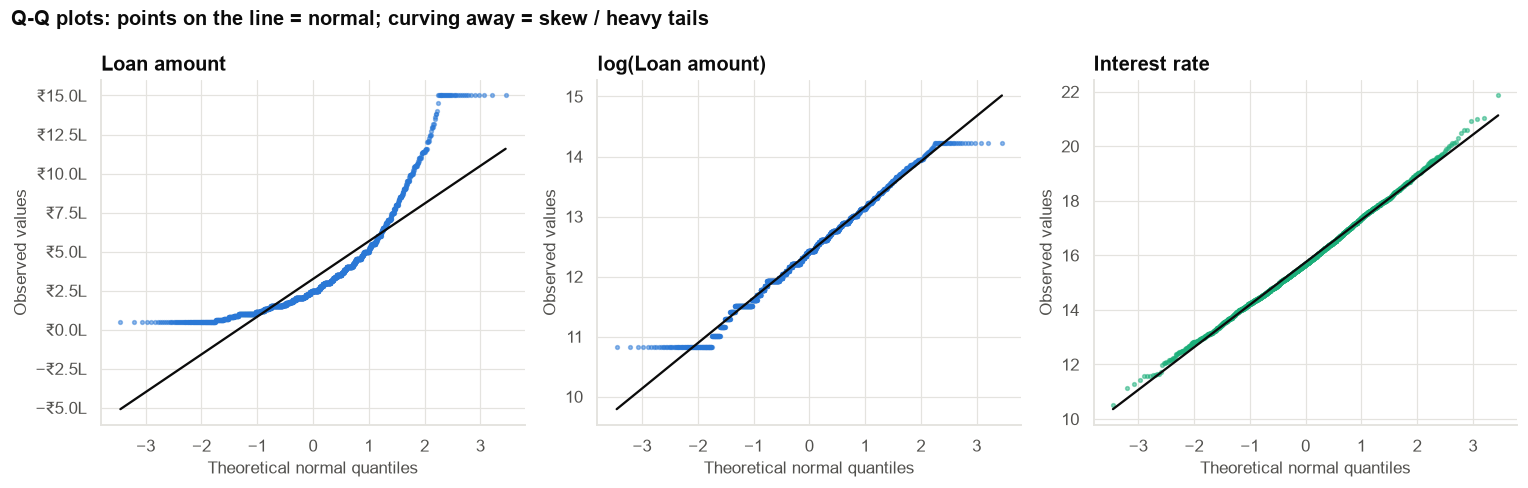

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
series = [("Loan amount", amt, PRIMARY), ("log(Loan amount)", np.log(amt), COLORS["blue"]),
          ("Interest rate", rate, COLORS["aqua"])]
for ax, (label, x, color) in zip(axes, series):
    (osm, osr), (slope, intercept, r) = stats.probplot(x, dist="norm")
    ax.scatter(osm, osr, s=6, color=color, alpha=0.5)
    ax.plot(osm, slope * osm + intercept, color=INK, lw=1.5)
    ax.set(title=f"{label}", xlabel="Theoretical normal quantiles", ylabel="Observed values")
    if label == "Loan amount":
        ax.yaxis.set_major_formatter(lakh_fmt)
fig.suptitle("Q-Q plots: points on the line = normal; curving away = skew / heavy tails",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig03_qq_plots", PATHS["figures"])
plt.show()

**Observation.** Loan amount bends sharply upward at the right end. The flat runs at both ends are the
₹50k product floor and the ₹15 lakh cap. log(loan amount) is much straighter apart from those two limits (the
small steps are the round-number heaping). Interest rate is close to the line, with slightly heavier tails than normal.

**Interpretation.** A **Q-Q (quantile-quantile) plot** compares the sorted data with what a normal distribution
would give. An upward curve on the right means the large values are larger than a normal distribution allows: a
long right tail. Loan amount is approximately **log-normal**.

**Business implication.** Any method that assumes *individual* loan amounts are normal, for example
"95% of loans are within mean ± 2 SD", will be wrong for this book. We check this directly below.

**Caveat.** With 2,500 points a formal normality test (Shapiro-Wilk, etc.) will reject normality for almost any
real variable, even trivial departures. That is why we rely on plots and ask *does the departure matter for
my method?* rather than *is it exactly normal?*

In [22]:
def empirical_rule(x):
    m, s = x.mean(), x.std()
    return pd.Series({f"within ±{k} SD": ((x > m - k * s) & (x < m + k * s)).mean() for k in (1, 2, 3)})

pd.DataFrame({"normal theory": [0.6827, 0.9545, 0.9973],
              "interest_rate": empirical_rule(rate).values,
              "loan_amount": empirical_rule(amt).values},
             index=["within ±1 SD", "within ±2 SD", "within ±3 SD"]).style.format("{:.1%}")

,normal theory,interest_rate,loan_amount
within ±1 SD,68.3%,68.3%,83.7%
within ±2 SD,95.5%,95.6%,94.6%
within ±3 SD,99.7%,99.7%,97.5%


For interest rate, the **68–95–99.7 rule** works almost exactly. For loan amount, ±1 SD captures far more than
68% of loans, and the ±2 SD band runs below zero. **The SD only has its "textbook" meaning for roughly normal
data.** For skewed data, describe spread with percentiles.

### Figure 4 — Comparing segments: boxplots and ECDFs

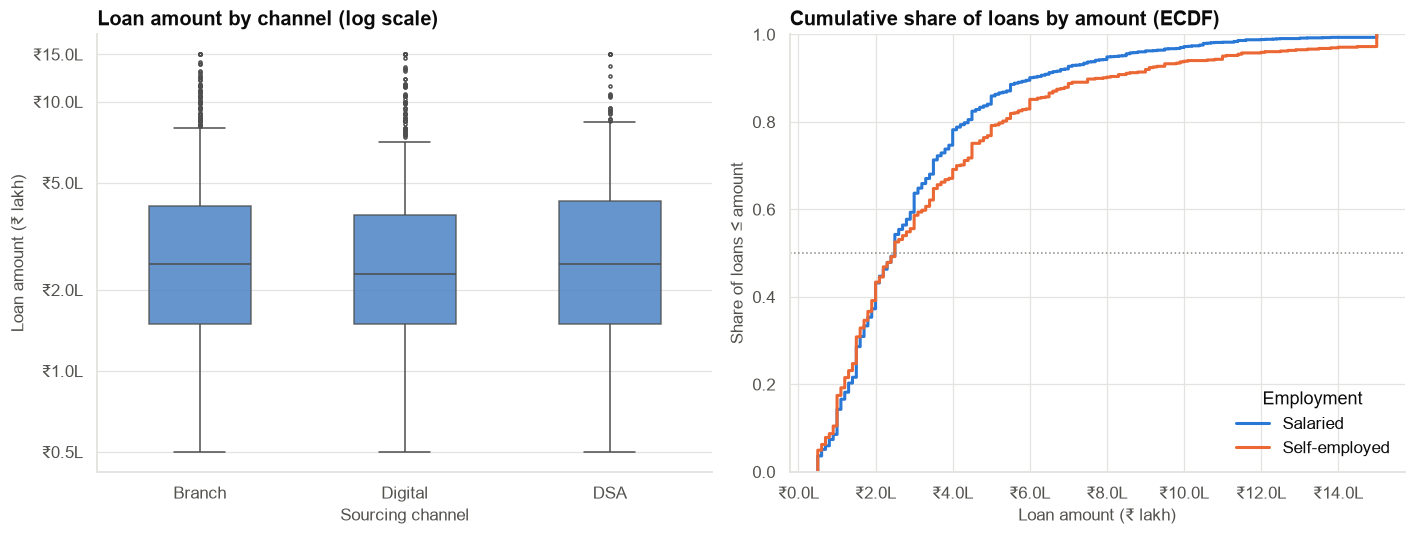

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
order = ["Branch", "Digital", "DSA"]
sns.boxplot(data=clean, x="channel", y="loan_amount", order=order, ax=axes[0], width=0.5,
            color=COLORS["blue"], fliersize=2, boxprops=dict(alpha=0.8))
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(lakh_fmt)
axes[0].yaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_yticks([50_000, 100_000, 200_000, 500_000, 1_000_000, 1_500_000])
axes[0].set(title="Loan amount by channel (log scale)", xlabel="Sourcing channel", ylabel="Loan amount (₹ lakh)")

for emp, color in zip(["Salaried", "Self-employed"], [COLORS["blue"], COLORS["orange"]]):
    sns.ecdfplot(clean.loc[clean["employment_type"] == emp, "loan_amount"], ax=axes[1], label=emp, color=color, lw=2)
axes[1].axhline(0.5, color=INK_MUTED, ls=":", lw=1)
axes[1].xaxis.set_major_formatter(lakh_fmt)
axes[1].set(title="Cumulative share of loans by amount (ECDF)", xlabel="Loan amount (₹ lakh)",
            ylabel="Share of loans ≤ amount")
axes[1].legend(title="Employment", loc="lower right")
fig.tight_layout()
save_fig(fig, "fig04_amount_by_segment", PATHS["figures"])
plt.show()

**Observation.** The three channels have similar medians and spreads of loan amount. The ECDF for self-employed
borrowers sits to the right at the top end: their largest loans are larger, and their spread is wider.

**Interpretation.** A **boxplot** shows the five-number summary at a glance (box = IQR, line = median, whiskers
≈ 1.5 × IQR, dots = values beyond). A log scale keeps the skewed tail readable. An **ECDF** (empirical cumulative
distribution function) shows, for any amount, the share of loans at or below it. Reading across at 0.5 gives
each group's median. ECDFs show *the whole distribution* without the binning choices a histogram needs.

**Business implication.** Channel does not change *how much* customers borrow much. If channels differ in risk,
it is not because DSA loans are bigger.

**Caveat.** These are visual impressions from a sample. Case 02 tests such differences formally.

### Figure 5 — 90+ DPD rate by segment, with uncertainty

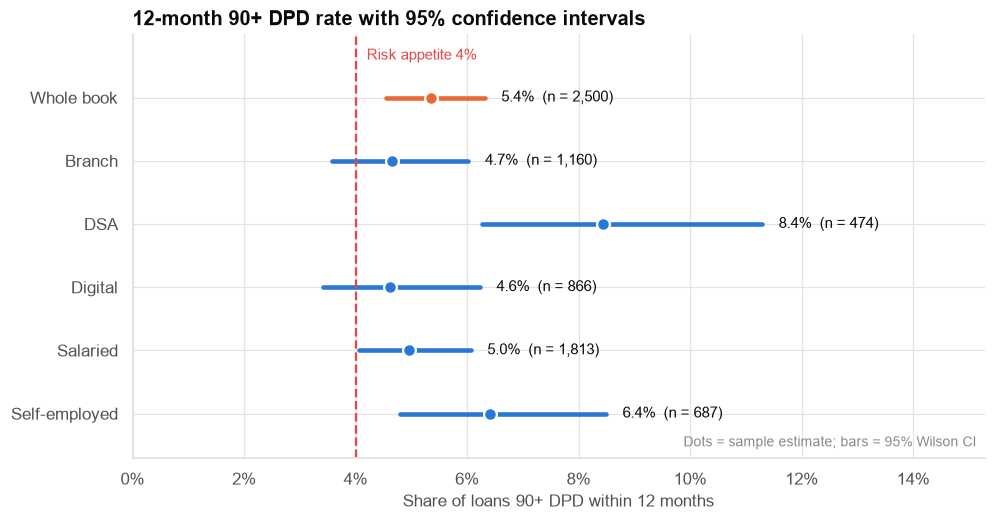

In [24]:
overall_k, overall_n = int(clean["dpd90_12m"].sum()), len(clean)
overall_ci = proportion_ci(overall_k, overall_n)
rows = [("Whole book", overall_ci["estimate"], overall_ci["lower"], overall_ci["upper"], overall_n)]
for (dim, lvl), r in seg.iterrows():
    rows.append((f"{lvl}", r["dpd90_rate"], r["dpd90_ci_low"], r["dpd90_ci_high"], int(r["loans"])))
plot_df = pd.DataFrame(rows, columns=["segment", "rate", "low", "high", "n"])

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(plot_df))[::-1]
colors = [HIGHLIGHT] + [PRIMARY] * (len(plot_df) - 1)
for yi, (_, r), c in zip(y, plot_df.iterrows(), colors):
    ax.plot([r["low"], r["high"]], [yi, yi], color=c, lw=3, solid_capstyle="round")
    ax.scatter(r["rate"], yi, s=70, color=c, zorder=3, edgecolor="white", linewidth=1.5)
    ax.text(r["high"] + 0.003, yi, f"{r['rate']:.1%}  (n = {r['n']:,})", va="center", fontsize=10)
ax.axvline(RISK_APPETITE_DPD90, color=COLORS["red"], ls="--", lw=1.5)
ax.text(RISK_APPETITE_DPD90 + 0.002, y.max() + 0.6, "Risk appetite 4%", color=COLORS["red"], ha="left", fontsize=10)
ax.set_yticks(y, plot_df["segment"])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0, plot_df["high"].max() + 0.04)
ax.set_ylim(-0.7, y.max() + 1.0)
ax.set(title="12-month 90+ DPD rate with 95% confidence intervals", xlabel="Share of loans 90+ DPD within 12 months")
add_note(ax, "Dots = sample estimate; bars = 95% Wilson CI", "lower right")
save_fig(fig, "fig05_default_rate_by_segment", PATHS["figures"])
plt.show()

**Observation.** The book-level 90+ DPD rate is about 5.4% and its whole confidence interval lies to the right
of the 4% appetite line. DSA loans stand out at about 8%. The smaller segments have wider intervals.

**Interpretation.** Each bar shows the range of underlying rates that are consistent with the sample. Bars
are wider for smaller segments: **uncertainty shrinks with sample size**, roughly as 1/√n.

**Business implication.** The headline risk number is above appetite, and the DSA channel is the most obvious
place to look.

**Caveat.** This chart does not show that the DSA channel *causes* higher delinquency. DSA customers may simply
be different (lower scores, higher DTI). Section 13 returns to this.

## Section 7A — From a sample to the whole book: sampling error and the Central Limit Theorem

Everything so far describes **2,500 loans**. The Board cares about **60,000 loans**. Before any inference we
need to understand the link.

- **Population:** all 60,000 loans in the book. Its true mean ticket size μ and true 90+ DPD rate p are fixed
  but unknown to us.
- **Sample:** the 2,500 loans Internal Audit reviewed. Its mean x̄ and rate p̂ are **estimates** of μ and p.
- **Sampling error:** x̄ ≠ μ simply because we looked at a subset. A different random sample would give a
  slightly different x̄. Sampling error is not a mistake. It is unavoidable, and **it can be quantified** if the
  sample was random.
- **Simple random sampling:** every loan had the same chance of selection. Audit did it the standard way: give
  every loan a random number from a **Uniform(0, 1)** distribution and keep the 2,500 smallest
  (`ORDER BY RANDOM() LIMIT 2500` in SQL). Because selection was random, the sample is representative *on
  average*, and the formulas below are valid. A convenience sample ("the files in the Mumbai office") would
  not have these guarantees. Case 18 covers sampling designs and biases in depth.

### 7A.1 Representativeness check

We can check representativeness on variables whose book-wide distribution we *do* know reliably. Channel and region
were not affected by the migration, so the loan system's MIS gives their true mix.

> **Teaching device.** Because the data is synthetic, we also have the full book (`_population_answer_key.csv.gz`).
> In real life you would only have the MIS mix for a few reliable fields. We use the answer key **only** to
> (1) get that mix, (2) demonstrate sampling and the CLT, and (3) check our estimates at the end. None of the
> analysis conclusions use it.

In [25]:
book = pd.read_csv(PATHS["data"] / "_population_answer_key.csv.gz")   # teaching only, see note above
rep_rows = []
for col in ["channel", "region", "employment_type"]:
    s_mix = clean[col].value_counts(normalize=True)
    b_mix = book[col].value_counts(normalize=True)
    for lvl in b_mix.index:
        rep_rows.append((col, lvl, b_mix[lvl], s_mix.get(lvl, 0.0)))
rep = pd.DataFrame(rep_rows, columns=["variable", "level", "book_share", "sample_share"])
rep["difference_pp"] = 100 * (rep["sample_share"] - rep["book_share"])
save_table(rep, "sample_vs_book_mix", PATHS["tables"], index=False)
rep.style.format({"book_share": "{:.1%}", "sample_share": "{:.1%}", "difference_pp": "{:+.1f}"})

,variable,level,book_share,sample_share,difference_pp
0,channel,Branch,44.9%,46.4%,+1.5
1,channel,Digital,35.7%,34.6%,-1.0
2,channel,DSA,19.4%,19.0%,-0.5
3,region,North,29.8%,30.4%,+0.6
4,region,South,28.1%,27.0%,-1.1
5,region,West,25.1%,25.9%,+0.8
6,region,East,17.0%,16.7%,-0.3
7,employment_type,Salaried,72.1%,72.5%,+0.5
8,employment_type,Self-employed,27.9%,27.5%,-0.5


Sample shares are within about ±1.5 percentage points of the book mix. That is the size of difference random
sampling produces by chance (the standard error of a 30% share with n = 2,500 is about 0.9 pp). Nothing suggests
the sample is skewed towards a channel or region.

### 7A.2 The Central Limit Theorem (CLT), by simulation

Loan amounts are strongly skewed. So why can we use a normal-based confidence interval for the *mean* loan
amount? The answer is the CLT:

> **Central Limit Theorem.** If you take many random samples of size n and compute each sample's mean, the
> distribution of those means is approximately **normal**, centred on the true mean μ, with standard deviation
> **σ / √n** (the *standard error*), **whatever the shape of the original data**, provided n is large enough.

"Large enough" depends on how skewed the data is. Let's watch it happen using the full book.

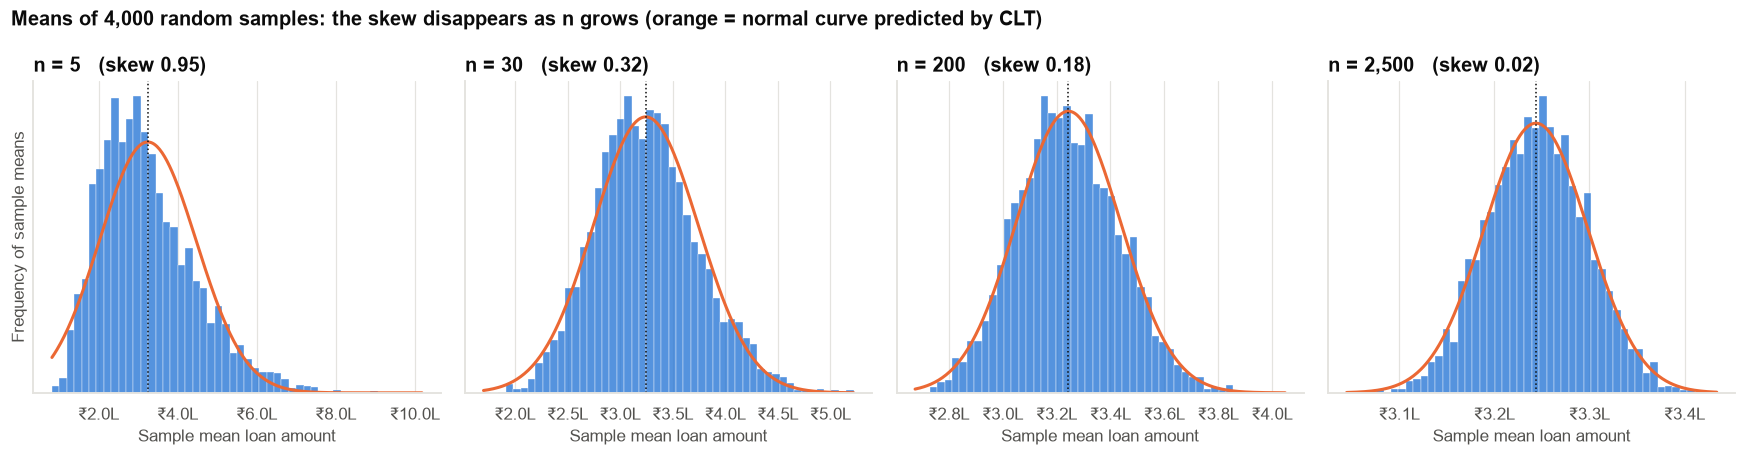

,mean_of_sample_means,sd_of_sample_means,CLT_standard_error,skew_of_sample_means
n,,,,
5,"324,726.000","123,313.012","122,457.127",0.954
30,"325,359.417","49,134.226","49,992.913",0.323
200,"324,147.138","19,021.142","19,362.172",0.183
2500,"324,502.797","5,260.027","5,476.449",0.023


In [26]:
pop_amt = book["loan_amount"].to_numpy()
mu, sigma = pop_amt.mean(), pop_amt.std()
sample_sizes = [5, 30, 200, 2_500]
n_reps = 4_000

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
clt_rows = []
for ax, n in zip(axes, sample_sizes):
    means = np.array([rng.choice(pop_amt, n, replace=False).mean() for _ in range(n_reps)])
    se_theory = sigma / np.sqrt(n)
    clt_rows.append((n, means.mean(), means.std(), se_theory, stats.skew(means)))
    ax.hist(means, bins=50, density=True, color=PRIMARY, alpha=0.8, edgecolor="white", linewidth=0.3)
    xs = np.linspace(means.min(), means.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, mu, se_theory), color=HIGHLIGHT, lw=2)
    ax.axvline(mu, color=INK, lw=1, ls=":")
    ax.xaxis.set_major_formatter(lakh_fmt)
    ax.set(title=f"n = {n:,}   (skew {stats.skew(means):.2f})", xlabel="Sample mean loan amount", yticks=[])
axes[0].set_ylabel("Frequency of sample means")
fig.suptitle("Means of 4,000 random samples: the skew disappears as n grows (orange = normal curve predicted by CLT)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig06_clt_simulation", PATHS["figures"])
plt.show()

pd.DataFrame(clt_rows, columns=["n", "mean_of_sample_means", "sd_of_sample_means", "CLT_standard_error",
                                "skew_of_sample_means"]).set_index("n")

What the simulation shows:

1. **Centre:** the sample means are centred on the true book mean (≈ ₹3.24 lakh) at every n. The sample mean is
   an **unbiased** estimator.
2. **Spread:** the spread of sample means matches σ/√n, as the CLT predicts. Quadrupling the sample size *halves*
   the standard error. (At n = 2,500 the simulated spread is about 4% smaller than σ/√n because we sample 4% of
   the book *without replacement*. That is the finite-population correction √(1 − n/N) from Section 9.) At n = 2,500 the standard error is about ₹5,500: a sample mean is typically within a few thousand rupees of the truth.
3. **Shape:** with n = 5 the sample means are still clearly right-skewed. By n = 200 they are close to normal,
   and at n = 2,500 the normal approximation is excellent.

**Why this matters:** the CLT is what allows confidence intervals and t-tests for the mean of non-normal
data. The requirement is that **the sample mean** is approximately normal, not the individual loans. With
2,500 loans, that is safely true here. With 15 loans from a skewed variable, it would not be, and we would use the
bootstrap (Case 23) or a different method.

## Section 8 — Statistical method selection

Before calculating anything, we state why we choose each method and what we rejected.

### Q4: Is the average ticket size different from the ₹3.0 lakh plan?

```text
Outcome            : loan_amount, continuous, right-skewed
Groups             : one sample, compared with a fixed target (₹300,000)
Estimand           : the MEAN. The plan uses average ticket × number of loans = total exposure,
                     so the business question is about the mean, not the median.
Direction          : two-sided. Being above OR below plan matters (capital vs. growth).
Sample             : n = 2,500, simple random sample
```

| Candidate | Tests… | Verdict |
|---|---|---|
| **One-sample t-test + t confidence interval** | the mean | ✅ **Selected.** Right estimand. Valid for skewed data at this n via the CLT. Gives an interval in rupees. |
| One-sample z-test | the mean, with a *known* population σ | ❌ σ is unknown. With n = 2,500 the t and z answers are practically identical anyway. |
| Wilcoxon signed-rank test | the pseudo-median (centre of symmetry) | ❌ Wrong estimand: it would answer "is the typical loan ₹3 lakh?", and it assumes symmetry, which we don't have. |
| Sign test | the median | ❌ Wrong estimand for an exposure question. Useful if the question were about the typical customer. |
| Bootstrap CI for the mean | the mean, no normality assumption | ✅ **Used as a robustness check** of the t-interval. |

> A common shortcut is "data is not normal → use a non-parametric test". Here it would give the right answer to
> the wrong question. **Choose the method from the estimand first, then check the assumptions.**

### Q5: Is the 90+ DPD rate above the 4% risk appetite?

```text
Outcome            : dpd90_12m, binary, so the parameter is a proportion p
Target             : 4% (risk appetite)
Direction          : ONE-sided (H1: p > 4%). The Board's question is "have we breached?",
                     and the direction was fixed BEFORE looking at the data.
Sample             : n = 2,500, about 130 events
```

| Candidate | Verdict |
|---|---|
| **Exact binomial test** | ✅ **Selected as the primary test.** Exact for any n, and no approximation to justify. |
| One-sample z-test for a proportion | ✅ Reported alongside, because it shows the mechanics (test statistic, critical value). Valid here since n·p₀ = 100 ≥ 10. |
| **Wilson confidence interval** | ✅ For the estimate. Better coverage than the textbook (Wald) interval, especially for small proportions. |
| Chi-square goodness-of-fit | ❌ Equivalent to the two-sided z-test. Adds nothing for one proportion. |

### Q6: Are DTI policy exceptions within the 1% limit?

A small proportion (roughly 0.5%, about a dozen events). The textbook **Wald interval p̂ ± 1.96·√(p̂(1−p̂)/n) is
unreliable when the count of events is small**. It can even go below zero. We use **Wilson** and show the
contrast.

### Q2: What is a typical loan?

We report the **median with a bootstrap CI**, because there is no simple textbook formula for the standard error
of a median. Case 23 covers the bootstrap in depth.

## Section 9 — Assumption checking

### One-sample t-interval / t-test for the mean loan amount

| # | Assumption | How we check | Result |
|---|---|---|---|
| 1 | **Independent observations** | Design: simple random sample; one row per loan after de-duplication | ✅ Satisfied by design |
| 2 | **Sample is small relative to the population**, or we apply a correction | n/N = 2,500 / 60,000 = 4.2% | ✅ The finite-population correction √(1 − n/N) = 0.98 would narrow the CI by 2%. We ignore it, which is slightly conservative. |
| 3 | **Sampling distribution of the mean ≈ normal** | CLT simulation (Fig. 6); bootstrap distribution below | ✅ n = 2,500 is far more than enough for this level of skew |
| 4 | **No data errors driving the mean** | Section 5: errors fixed; large loans verified as legitimate | ✅ |

Note what is **not** an assumption: *individual loan amounts do not need to be normal.* Many learners check a
histogram of the raw data, see skew, and wrongly abandon the t-test.

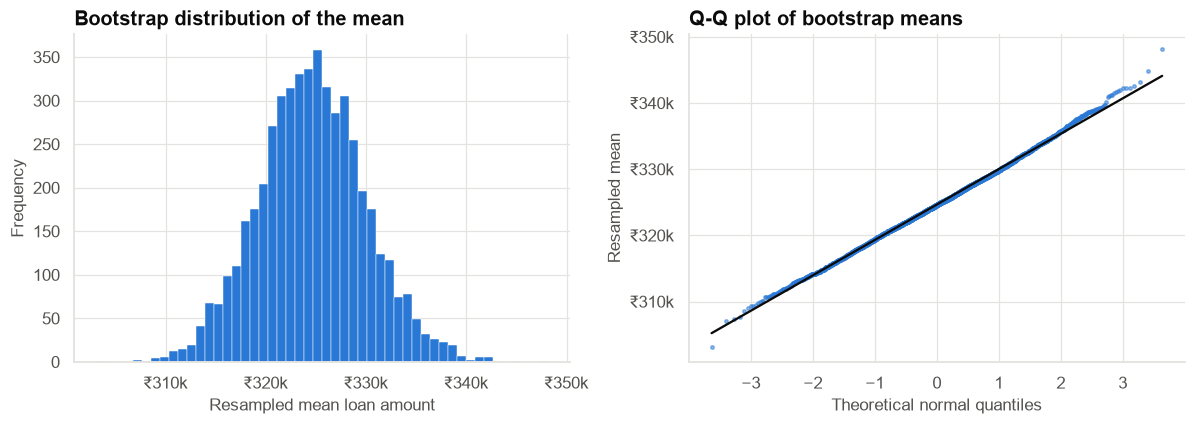

Skewness of bootstrap means: 0.108  (raw loan amounts: 2.04)


In [27]:
# Evidence for assumption 3 from our own sample: the bootstrap distribution of the mean.
boot_means = np.array([rng.choice(amt.to_numpy(), len(amt), replace=True).mean() for _ in range(5_000)])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(boot_means, bins=50, color=PRIMARY, edgecolor="white", linewidth=0.3)
axes[0].xaxis.set_major_formatter(thousands_formatter("₹", "k", 1e3, 0))
axes[0].set(title="Bootstrap distribution of the mean", xlabel="Resampled mean loan amount", ylabel="Frequency")
(osm, osr), (sl, ic, _) = stats.probplot(boot_means, dist="norm")
axes[1].scatter(osm, osr, s=5, color=PRIMARY, alpha=0.5)
axes[1].plot(osm, sl * osm + ic, color=INK, lw=1.5)
axes[1].yaxis.set_major_formatter(thousands_formatter("₹", "k", 1e3, 0))
axes[1].set(title="Q-Q plot of bootstrap means", xlabel="Theoretical normal quantiles", ylabel="Resampled mean")
fig.tight_layout()
plt.show()
print(f"Skewness of bootstrap means: {stats.skew(boot_means):.3f}  (raw loan amounts: {stats.skew(amt):.2f})")

The bootstrap distribution of the mean is symmetric and lies on the Q-Q line. The normal approximation the
t-interval relies on is sound here.

### One-sample proportion tests and intervals

| # | Assumption | Check | Result |
|---|---|---|---|
| 1 | Independent loans; each is 0/1 | SRS; flag is binary | ✅ |
| 2 | Same underlying probability across loans | **Not literally true**: DSA loans are riskier. The test still validly targets the *book-level* rate, which is what the Board asks about. | ✅ for this question |
| 3 | Normal approximation (z-test only) | n·p₀ = 2,500 × 0.04 = 100 ≥ 10 and n·(1−p₀) ≥ 10 | ✅. The exact binomial test needs no approximation anyway. |
| 4 | Outcome fully observed | All sampled loans have ≥ 12 months on book | ✅ (by audit design) |

**What if an assumption failed?** If audit had sampled *clustered* files (say, 50 branches and every loan in
them), observations would not be independent. The standard errors below would be too small and we would need
cluster-robust methods. If the outcome were not yet observable (loans younger than 12 months), we would need
time-to-event methods (Case 26). Neither applies here, so we proceed.

## Section 10 — Analysis

### 10.1 Confidence interval for the mean ticket size, by hand first

In [28]:
n = len(amt)
x_bar = amt.mean()
s = amt.std(ddof=1)                         # sample SD (n-1 in the denominator)
se = s / np.sqrt(n)                         # standard error of the mean
t_crit = stats.t.ppf(0.975, df=n - 1)       # 97.5th percentile of t with n-1 df
ci_low, ci_high = x_bar - t_crit * se, x_bar + t_crit * se

print(f"n = {n:,}   mean = {fmt_money(x_bar)}   SD = {fmt_money(s)}")
print(f"standard error = SD / sqrt(n) = {fmt_money(s)} / {np.sqrt(n):.1f} = {fmt_money(se)}")
print(f"t critical value (95%, df = {n - 1}) = {t_crit:.4f}   (the normal value would be 1.9600)")
print(f"95% CI = mean ± t × SE = {fmt_money(x_bar)} ± {fmt_money(t_crit * se)}  ->  [{fmt_money(ci_low)}, {fmt_money(ci_high)}]")

ci_mean = mean_ci(amt)
ci_mean_boot = bootstrap_ci(amt, statistic=np.mean, seed=1)
print(f"\nShared helper (t)    : [{fmt_money(ci_mean['lower'])}, {fmt_money(ci_mean['upper'])}]")
print(f"Bootstrap percentile : [{fmt_money(ci_mean_boot['lower'])}, {fmt_money(ci_mean_boot['upper'])}]  <- agrees")

n = 2,500   mean = ₹324,580   SD = ₹270,745
standard error = SD / sqrt(n) = ₹270,745 / 50.0 = ₹5,415
t critical value (95%, df = 2499) = 1.9609   (the normal value would be 1.9600)
95% CI = mean ± t × SE = ₹324,580 ± ₹10,618  ->  [₹313,962, ₹335,198]



Shared helper (t)    : [₹313,962, ₹335,198]
Bootstrap percentile : [₹313,928, ₹335,168]  <- agrees


### 10.2 Confidence interval for the median ("typical") loan

In [29]:
ci_median = bootstrap_ci(amt, statistic=np.median, seed=2)
print(f"Median loan amount = {fmt_money(ci_median['estimate'])}, "
      f"95% bootstrap CI [{fmt_money(ci_median['lower'])}, {fmt_money(ci_median['upper'])}]")

Median loan amount = ₹250,000, 95% bootstrap CI [₹240,000, ₹250,000]


The interval for the median is narrow and "steppy": because of heaping, the median can only land on a few round
values, so the bootstrap interval runs from ₹2.4 to ₹2.5 lakh. Bootstrap intervals for medians of heaped data
are coarse. That is a property of the data, not a bug.

### 10.3 Confidence interval for the 90+ DPD rate: Wald vs Wilson

In [30]:
k = int(clean["dpd90_12m"].sum())
p_hat = k / n
se_p = np.sqrt(p_hat * (1 - p_hat) / n)
z975 = stats.norm.ppf(0.975)
wald = (p_hat - z975 * se_p, p_hat + z975 * se_p)
ci_dpd = proportion_ci(k, n, method="wilson")
ci_dpd_exact = proportion_ci(k, n, method="beta")   # Clopper-Pearson "exact" interval

print(f"Defaults: {k} of {n:,} loans  ->  p̂ = {p_hat:.4f} ({p_hat:.2%})")
print(f"Standard error = sqrt(p̂(1-p̂)/n) = {se_p:.4f}")
print(f"Wald 95% CI            : [{wald[0]:.2%}, {wald[1]:.2%}]")
print(f"Wilson 95% CI          : [{ci_dpd['lower']:.2%}, {ci_dpd['upper']:.2%}]")
print(f"Clopper-Pearson 95% CI : [{ci_dpd_exact['lower']:.2%}, {ci_dpd_exact['upper']:.2%}]")

Defaults: 134 of 2,500 loans  ->  p̂ = 0.0536 (5.36%)
Standard error = sqrt(p̂(1-p̂)/n) = 0.0045
Wald 95% CI            : [4.48%, 6.24%]
Wilson 95% CI          : [4.54%, 6.31%]
Clopper-Pearson 95% CI : [4.51%, 6.32%]


With about 130 events all three methods agree to within a tenth of a percentage point. The choice of
method matters when the count is small, as in the next calculation.

### 10.4 Policy exceptions: a small proportion

In [31]:
exc = clean["dti"] > DTI_POLICY_CAP
k_exc = int(exc.sum())
p_exc = k_exc / n
se_exc = np.sqrt(p_exc * (1 - p_exc) / n)
ci_exc = proportion_ci(k_exc, n, method="wilson")
print(f"Policy exceptions (DTI > {DTI_POLICY_CAP:.0%}): {k_exc} of {n:,} = {p_exc:.2%}")
print(f"Wald 95% CI   : [{p_exc - z975 * se_exc:.2%}, {p_exc + z975 * se_exc:.2%}]")
print(f"Wilson 95% CI : [{ci_exc['lower']:.2%}, {ci_exc['upper']:.2%}]   (Board limit: {EXCEPTION_LIMIT:.0%})")

Policy exceptions (DTI > 65%): 11 of 2,500 = 0.44%
Wald 95% CI   : [0.18%, 0.70%]
Wilson 95% CI : [0.25%, 0.79%]   (Board limit: 1%)


In [32]:
# Why Wilson? Coverage of the two methods when the true rate is small (p = 0.5%) and n = 2,500.
true_p, sims = 0.005, 20_000
ks = rng.binomial(n, true_p, size=sims)
ph = ks / n
wald_cover = np.mean((ph - z975 * np.sqrt(ph * (1 - ph) / n) <= true_p) & (true_p <= ph + z975 * np.sqrt(ph * (1 - ph) / n)))
wl, wu = proportion_confint(ks, n, alpha=0.05, method="wilson")
wilson_cover = np.mean((wl <= true_p) & (true_p <= wu))
print(f"Actual coverage of a nominal 95% interval when p = 0.5%:  Wald {wald_cover:.1%}   Wilson {wilson_cover:.1%}")

Actual coverage of a nominal 95% interval when p = 0.5%:  Wald 92.3%   Wilson 95.7%

A "95%" Wald interval for a rare event actually covers the truth noticeably less often than 95% of the time.
The Wilson interval stays close to its promise. In fraud, default and complaint rates (rare events), **use Wilson
(or exact) intervals**.

The whole Wilson interval for policy exceptions lies **below the 1% limit**, so we can say with confidence
that the book is within the exception limit.

### 10.5 What a 95% confidence interval actually means

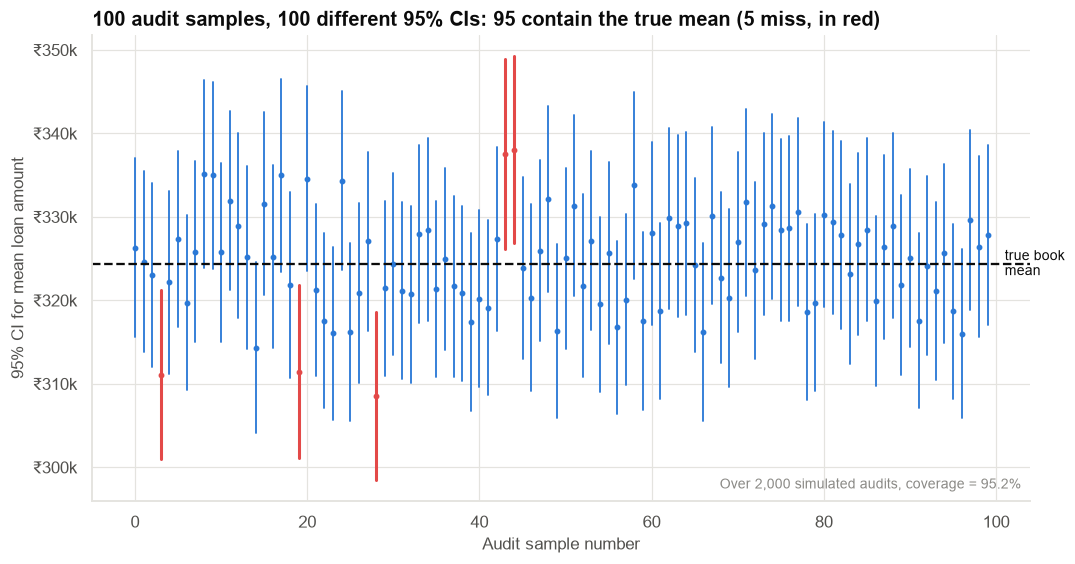

In [33]:
# Draw 100 independent audit samples from the book, compute a 95% t-interval from each,
# and check how many intervals contain the true book mean.
n_show = 100
intervals = []
for _ in range(n_show):
    smp = rng.choice(pop_amt, n, replace=False)
    c = mean_ci(smp)
    intervals.append((c["lower"], c["estimate"], c["upper"]))
intervals = np.array(intervals)
covers = (intervals[:, 0] <= mu) & (mu <= intervals[:, 2])

# Long-run coverage over many more samples (no plotting)
n_long = 2_000
hits = 0
for _ in range(n_long):
    c = mean_ci(rng.choice(pop_amt, n, replace=False))
    hits += c["lower"] <= mu <= c["upper"]
long_run_coverage = hits / n_long

fig, ax = plt.subplots(figsize=(11, 5.5))
for i, (lo, est, hi) in enumerate(intervals):
    color = PRIMARY if covers[i] else COLORS["red"]
    ax.plot([i, i], [lo, hi], color=color, lw=2 if not covers[i] else 1.2)
    ax.scatter(i, est, s=8, color=color)
ax.axhline(mu, color=INK, lw=1.5, ls="--")
ax.text(n_show + 1, mu, "true book\nmean", va="center", fontsize=9)
ax.yaxis.set_major_formatter(thousands_formatter("₹", "k", 1e3, 0))
ax.set(title=f"100 audit samples, 100 different 95% CIs: {covers.sum()} contain the true mean ({(~covers).sum()} miss, in red)",
       xlabel="Audit sample number", ylabel="95% CI for mean loan amount")
add_note(ax, f"Over {n_long:,} simulated audits, coverage = {long_run_coverage:.1%}", "lower right")
save_fig(fig, "fig07_ci_coverage", PATHS["figures"])
plt.show()

**This is the correct meaning of "95% confidence":** the *procedure* produces intervals that capture the true
value in about 95% of samples. Our one audit produced one interval. We do not know whether it is one of the
"blue" ones or one of the rare "red" ones, but the method is right 95% of the time.

| Statement | Correct? |
|---|---|
| "We are 95% confident the book's average ticket is between ₹3.14 and ₹3.35 lakh." | ✅ Standard, acceptable business phrasing (meaning: the method is right 95% of the time) |
| "If we repeated the audit many times, 95% of the intervals would contain the true average." | ✅ The precise definition |
| "95% of loans are between ₹3.14 and ₹3.35 lakh." | ❌ **The most common misreading.** The CI is about the *average*, not individual loans. 95% of individual loans span about ₹0.5 – ₹11.3 lakh (see below). |
| "There is a 95% probability that the true mean is in *this* interval." | ⚠️ Strictly speaking, no. The true mean is fixed and is either in it or not. This intuition belongs to the Bayesian credible interval (Case 24). Executives use this phrasing anyway, and it rarely causes harm. |
| "The true mean is definitely between ₹3.14 and ₹3.35 lakh." | ❌ About 5% of such intervals miss. |
| "A value outside the CI is impossible." | ❌ Only *less consistent with the data*. |
| "A wider CI means a worse estimate." | ⚠️ A wider CI means *more uncertainty*, usually from a smaller n or noisier data. It is honest, not worse. |

In [34]:
ref_low, ref_high = amt.quantile([0.025, 0.975])
print(f"Range covering the middle 95% of INDIVIDUAL loans : {fmt_money(ref_low)} to {fmt_money(ref_high)}")
print(f"95% confidence interval for the AVERAGE loan       : {fmt_money(ci_mean['lower'])} to {fmt_money(ci_mean['upper'])}")

Range covering the middle 95% of INDIVIDUAL loans : ₹50,000 to ₹1,130,000
95% confidence interval for the AVERAGE loan       : ₹313,962 to ₹335,198


Same data, same "95%", two very different ranges, because they answer different questions. Always say which
one you are showing.

### 10.6 Hypothesis test 1: is the average ticket size equal to the ₹3.0 lakh plan?

**The logic of a hypothesis test, in one paragraph.** We assume a "boring" world, the **null hypothesis H₀**:
*the true average ticket is exactly ₹3.0 lakh, and the sample mean differs from it only by sampling noise.* We
then ask: *if H₀ were true, how surprising would a sample mean as far from ₹3.0 lakh as ours be?* That probability
is the **p-value**. If it is very small (below a threshold **α** we choose in advance, conventionally 0.05),
the data is hard to reconcile with H₀ and we reject it in favour of the **alternative H₁**.

- H₀: μ = ₹300,000  H₁: μ ≠ ₹300,000  (two-sided)  α = 0.05
- **Test statistic:** t = (x̄ − 300,000) / SE. It counts *how many standard errors* the sample mean is from the
  target.

In [35]:
t_stat = (x_bar - PLAN_AVG_TICKET) / se
p_two_sided = 2 * stats.t.sf(abs(t_stat), df=n - 1)
print(f"t = ({fmt_money(x_bar)} - {fmt_money(PLAN_AVG_TICKET)}) / {fmt_money(se)} = {t_stat:.2f}")
print(f"Critical values at alpha = 0.05 (two-sided): ±{t_crit:.3f}  ->  |t| = {abs(t_stat):.2f} "
      f"{'>' if abs(t_stat) > t_crit else '<='} {t_crit:.3f}")
print(f"p-value = {p_two_sided:.2e}")

check = stats.ttest_1samp(amt, PLAN_AVG_TICKET)
print(f"scipy.stats.ttest_1samp: t = {check.statistic:.2f}, p = {check.pvalue:.2e}  <- matches")

diff = x_bar - PLAN_AVG_TICKET
diff_ci = (ci_mean["lower"] - PLAN_AVG_TICKET, ci_mean["upper"] - PLAN_AVG_TICKET)
cohen_d = diff / s
extra_exposure = BOOK_SIZE * diff
extra_exposure_ci = (BOOK_SIZE * diff_ci[0], BOOK_SIZE * diff_ci[1])
print(f"\nDifference from plan: {fmt_money(diff)} per loan ({diff / PLAN_AVG_TICKET:+.1%}), "
      f"95% CI [{fmt_money(diff_ci[0])}, {fmt_money(diff_ci[1])}]")
print(f"Standardised effect size (Cohen's d) = {cohen_d:.3f}")
print(f"Implied extra exposure on {BOOK_SIZE:,} loans: ₹{extra_exposure / 1e7:,.0f} crore "
      f"(95% CI ₹{extra_exposure_ci[0] / 1e7:,.0f} – ₹{extra_exposure_ci[1] / 1e7:,.0f} crore)")

t = (₹324,580 - ₹300,000) / ₹5,415 = 4.54
Critical values at alpha = 0.05 (two-sided): ±1.961  ->  |t| = 4.54 > 1.961
p-value = 5.91e-06
scipy.stats.ttest_1samp: t = 4.54, p = 5.91e-06  <- matches

Difference from plan: ₹24,580 per loan (+8.2%), 95% CI [₹13,962, ₹35,198]
Standardised effect size (Cohen's d) = 0.091
Implied extra exposure on 60,000 loans: ₹147 crore (95% CI ₹84 – ₹211 crore)


### 10.7 Hypothesis test 2: has the book breached the 4% risk appetite?

- H₀: p ≤ 0.04 (within appetite)  H₁: p > 0.04 (breach)  α = 0.05, **one-sided**
- Under H₀ (at the boundary p = 0.04), the sample rate p̂ is approximately normal with standard error
  √(0.04 × 0.96 / 2,500).

In [36]:
p0 = RISK_APPETITE_DPD90
se0 = np.sqrt(p0 * (1 - p0) / n)                  # SE under H0: uses p0, not p_hat
z_stat = (p_hat - p0) / se0
z_crit = stats.norm.ppf(0.95)                    # one-sided 5% critical value
p_z = stats.norm.sf(z_stat)
critical_rate = p0 + z_crit * se0
exact = stats.binomtest(k, n, p0, alternative="greater")

print(f"Observed rate p̂ = {p_hat:.2%}   SE under H0 = {se0:.4f}")
print(f"z = ({p_hat:.4f} - {p0}) / {se0:.4f} = {z_stat:.2f}   one-sided critical value = {z_crit:.3f}")
print(f"Equivalently: reject H0 if the observed rate exceeds {critical_rate:.2%}")
print(f"p-value (z approximation) = {p_z:.5f}")
print(f"p-value (exact binomial)  = {exact.pvalue:.5f}")
print(f"One-sided 95% lower confidence bound for p (exact): {exact.proportion_ci(confidence_level=0.95).low:.2%}")

Observed rate p̂ = 5.36%   SE under H0 = 0.0039


z = (0.0536 - 0.04) / 0.0039 = 3.47   one-sided critical value = 1.645
Equivalently: reject H0 if the observed rate exceeds 4.64%
p-value (z approximation) = 0.00026
p-value (exact binomial)  = 0.00053
One-sided 95% lower confidence bound for p (exact): 4.64%


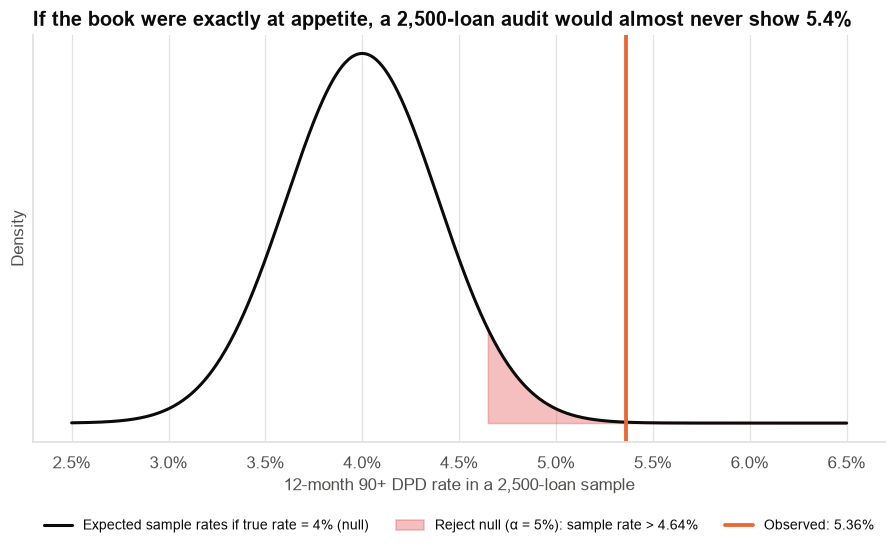

In [37]:
# Visualise the test: the sampling distribution of p̂ IF the true rate were exactly 4%.
xs = np.linspace(0.025, 0.065, 500)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(xs, stats.norm.pdf(xs, p0, se0), color=INK, lw=2, label="Expected sample rates if true rate = 4% (null)")
reject = xs >= critical_rate
ax.fill_between(xs[reject], stats.norm.pdf(xs[reject], p0, se0), color=COLORS["red"], alpha=0.35,
                label=f"Reject null (α = 5%): sample rate > {critical_rate:.2%}")
ax.axvline(p_hat, color=HIGHLIGHT, lw=2.5, label=f"Observed: {p_hat:.2%}")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set(title="If the book were exactly at appetite, a 2,500-loan audit would almost never show 5.4%",
       xlabel="12-month 90+ DPD rate in a 2,500-loan sample", ylabel="Density", yticks=[])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=9)
save_fig(fig, "fig08_appetite_test", PATHS["figures"])
plt.show()

#### Type I and Type II errors, in Board language

| | **Truth: within appetite** (p ≤ 4%) | **Truth: breached** (p > 4%) |
|---|---|---|
| **We report "breach"** | **Type I error (false alarm)**, probability ≤ α = 5%. Cost: unnecessary tightening of credit, lost good business, a Board escalation that was not needed. | ✅ Correct detection, probability = **power** |
| **We report "within appetite"** | ✅ Correct | **Type II error (missed breach)**, probability = β. Cost: losses keep accumulating, and a regulatory or reputational problem surfaces later. |

α is chosen by us. β depends on the sample size and on *how far* the truth is from 4%. How good was this
audit at spotting a breach?

In [38]:
def power_one_sided(true_p, n, p0=p0, alpha=0.05):
    # P(p̂ exceeds the critical rate | true rate = true_p), normal approximation.
    crit = p0 + stats.norm.ppf(1 - alpha) * np.sqrt(p0 * (1 - p0) / n)
    return stats.norm.sf((crit - true_p) / np.sqrt(true_p * (1 - true_p) / n))

power_tbl = pd.DataFrame({f"n = {m:,}": [power_one_sided(tp, m) for tp in (0.045, 0.05, 0.055, 0.06)]
                          for m in (500, 1_000, 2_500, 5_000)},
                         index=["true rate 4.5%", "true rate 5.0%", "true rate 5.5%", "true rate 6.0%"])
power_tbl.style.format("{:.0%}")

,n = 500,"n = 1,000","n = 2,500","n = 5,000"
true rate 4.5%,15%,21%,36%,56%
true rate 5.0%,33%,49%,79%,96%
true rate 5.5%,52%,75%,97%,100%
true rate 6.0%,70%,90%,100%,100%


Reading the table: if the true rate were 5.0%, a 2,500-loan audit flags the breach about 80% of the time, so a
1-in-5 chance of missing it. If the true rate were 4.5%, detection drops to about 36%, roughly one in three. **A non-significant result
from a small audit is weak evidence of compliance.** This is the subject of Cases 04 and 22 (power and sample
size); keep it in mind whenever someone says "the test was not significant, so we are fine".

## Section 11 — Results

All key estimates in one table, with uncertainty, as a reviewer would want them.

In [39]:
results = pd.DataFrame([
    {"metric": "Mean ticket size (₹)", "estimate": x_bar, "ci_low": ci_mean["lower"], "ci_high": ci_mean["upper"],
     "se": se, "benchmark": PLAN_AVG_TICKET, "test": "one-sample t (two-sided)", "statistic": t_stat, "p_value": p_two_sided},
    {"metric": "Median ticket size (₹)", "estimate": ci_median["estimate"], "ci_low": ci_median["lower"],
     "ci_high": ci_median["upper"], "se": ci_median["se"], "benchmark": np.nan, "test": "bootstrap CI", "statistic": np.nan, "p_value": np.nan},
    {"metric": "12m 90+ DPD rate", "estimate": p_hat, "ci_low": ci_dpd["lower"], "ci_high": ci_dpd["upper"],
     "se": se_p, "benchmark": p0, "test": "exact binomial, one-sided H1: p > 4% (z shown)", "statistic": z_stat, "p_value": exact.pvalue},
    {"metric": "DTI policy-exception rate", "estimate": p_exc, "ci_low": ci_exc["lower"], "ci_high": ci_exc["upper"],
     "se": se_exc, "benchmark": EXCEPTION_LIMIT, "test": "Wilson CI vs limit", "statistic": np.nan, "p_value": np.nan},
]).set_index("metric")
save_table(results, "key_results", PATHS["tables"])

fmt = results.copy().astype(object)
for m in fmt.index:
    money = "₹" in m
    f = (lambda v: fmt_money(v)) if money else (lambda v: f"{v:.2%}")
    for c in ["estimate", "ci_low", "ci_high", "se", "benchmark"]:
        fmt.loc[m, c] = "" if pd.isna(results.loc[m, c]) else f(results.loc[m, c])
    fmt.loc[m, "statistic"] = "" if pd.isna(results.loc[m, "statistic"]) else f"{results.loc[m, 'statistic']:.2f}"
    fmt.loc[m, "p_value"] = "" if pd.isna(results.loc[m, "p_value"]) else fmt_p(results.loc[m, "p_value"])
fmt

,estimate,ci_low,ci_high,se,benchmark,test,statistic,p_value
metric,,,,,,,,
Mean ticket size (₹),"₹324,580","₹313,962","₹335,198","₹5,415","₹300,000",one-sample t (two-sided),4.54,< 0.001
Median ticket size (₹),"₹250,000","₹240,000","₹250,000","₹4,681",,bootstrap CI,,
12m 90+ DPD rate,5.36%,4.54%,6.31%,0.45%,4.00%,"exact binomial, one-sided H1: p > 4% (z shown)",3.47,< 0.001
DTI policy-exception rate,0.44%,0.25%,0.79%,0.13%,1.00%,Wilson CI vs limit,,


In [40]:
print(f"Effect size, ticket vs plan: +{fmt_money(diff)} per loan ({diff / PLAN_AVG_TICKET:+.1%}); Cohen's d = {cohen_d:.2f}")
print(f"Effect size, DPD vs appetite: +{100 * (p_hat - p0):.2f} percentage points; "
      f"relative excess {p_hat / p0 - 1:+.0%} (95% CI {ci_dpd['lower'] / p0 - 1:+.0%} to {ci_dpd['upper'] / p0 - 1:+.0%})")

Effect size, ticket vs plan: +₹24,580 per loan (+8.2%); Cohen's d = 0.09
Effect size, DPD vs appetite: +1.36 percentage points; relative excess +34% (95% CI +14% to +58%)


### Validation: did the sample tell the truth?

In real work you never see the true values. Here we can, so we use the answer key to **validate** that the
methods behaved as promised. This is the only place the answer key is compared with results.

In [41]:
truth = {
    "Mean ticket size (₹)": book["loan_amount"].mean(),
    "Median ticket size (₹)": book["loan_amount"].median(),
    "12m 90+ DPD rate": book["dpd90_12m"].mean(),
    "DTI policy-exception rate": (book["dti"] > DTI_POLICY_CAP).mean(),
}
val = results[["estimate", "ci_low", "ci_high"]].copy()
val["true_book_value"] = pd.Series(truth)
val["sampling_error"] = val["estimate"] - val["true_book_value"]
val["ci_contains_truth"] = (val["ci_low"] <= val["true_book_value"]) & (val["true_book_value"] <= val["ci_high"])
save_table(val, "validation_against_book", PATHS["tables"])
val

,estimate,ci_low,ci_high,true_book_value,sampling_error,ci_contains_truth
metric,,,,,,
Mean ticket size (₹),"324,580.000","313,961.830","335,198.170","324,372.833",207.167,True
Median ticket size (₹),"250,000.000","240,000.000","250,000.000","250,000.000",0.000,True
12m 90+ DPD rate,0.054,0.045,0.063,0.051,0.003,True
DTI policy-exception rate,0.004,0.002,0.008,0.003,0.001,True


Every interval contains the true book value, and every sampling error is small relative to its CI width. This is
what we expect most of the time (about 95% per interval), not a guarantee. Note also that our sample's 90+ DPD
rate (5.4%) is *above* the true 5.1%: a modest positive sampling error, well inside the CI. The conclusion
"above appetite" still holds for the true value.

## Section 12 — Interpretation

**Average ticket size.** The audited sample's mean loan amount is **₹3.25 lakh** (95% CI ₹3.14 – ₹3.35 lakh).
The one-sample t-test gives t ≈ 4.5 (the sample mean is 4.5 standard errors above the plan), p < 0.001. If the true book average were exactly ₹3.0 lakh, a sample
average this far away would almost never occur by chance, so we reject the null hypothesis that the average
ticket equals the plan. The estimated excess is **about ₹24,600 per loan (+8%)**, with a CI of roughly
₹14,000 – ₹35,000. Cohen's d is about 0.09, "very small" by textbook conventions. **This is exactly why textbook
effect-size labels should not be used as business thresholds.** Spread over 60,000 loans, ₹24,600 per loan is
about **₹150 crore** of additional exposure versus plan (CI ≈ ₹85 – ₹210 crore). That matters for capital and
provisioning even though it is "small" per loan.

**Typical ticket.** The median loan is **₹2.5 lakh** (95% bootstrap CI ₹2.4 – ₹2.5 lakh), about 23% below the
mean. The gap comes from right skew: a minority of large loans (≥ ₹5 lakh: about 16% of loans, 40% of exposure)
pulls the mean up. Both numbers are correct; they answer different questions.

**Delinquency vs appetite.** 134 of 2,500 audited loans (**5.4%**, 95% Wilson CI **4.5% – 6.3%**) went 90+ DPD
within 12 months. The exact one-sided binomial test of H₀: p ≤ 4% gives p ≈ 0.0005. If the book were exactly at
appetite, an audit showing 5.4% or more would happen about once in two thousand audits. The data provide
**strong evidence that the book-level 12-month 90+ DPD rate exceeds the 4% risk appetite**. The best estimate is
that it exceeds it by about 1.4 percentage points (a third above appetite), plausibly anywhere from +0.5 to +2.3
points.

**What the p-value is not.** p ≈ 0.0005 is *not* "a 0.05% chance that the book is within appetite". A p-value is
computed *assuming* H₀ is true, so it cannot be the probability that H₀ is true. It measures how incompatible
the data is with H₀.

**Policy exceptions.** 11 loans (0.44%, Wilson CI 0.25% – 0.79%) exceed the 65% DTI cap. The entire interval is
below the 1% limit, so the book is within the exception limit, and the result does not depend on the choice of
interval method.

**Shape and dispersion.** Loan amounts and incomes are strongly right-skewed and heavy-tailed (approximately
log-normal). Interest rates are approximately normal around 15.7% (SD 1.6 pp). Credit scores are left-skewed and
truncated by the approval policy. For skewed variables we report medians and percentiles; for symmetric ones,
mean ± SD is fine.

## Section 13 — What can we say?

### ✅ We can confidently say
- The audit extract had **fixable data-quality problems** (6 duplicates, 5 unit-error rates, 4 annual incomes,
  3 impossible ages, 5% "−1" credit-score codes). After cleaning, the sample is fit for book-level reporting.
- A **typical** personal loan is about ₹2.5 lakh, at about 15.7% p.a., over 36 months.
- The book is **right-skewed**: ~16% of loans (≥ ₹5 lakh) carry ~40% of exposure.
- The **average ticket** is between about ₹3.14 and ₹3.35 lakh (95% CI), above the ₹3.0 lakh plan.
- **DTI policy exceptions** are within the 1% Board limit.

### 📊 We have (strong) evidence that
- The book's **12-month 90+ DPD rate is above the 4% risk appetite**: estimate 5.4%, 95% CI 4.5–6.3%,
  one-sided p ≈ 0.0005.
- **DSA-sourced** loans have a materially higher 90+ DPD rate (~8%) than other channels (~4.6%). This is descriptive
  evidence from non-overlapping intervals; Case 02 tests it formally.

### ❌ We cannot conclude
- **Why** the book is above appetite. The DSA channel is *associated* with higher delinquency, but DSA customers
  may differ in score, DTI or employment. We have not separated those factors, so "the DSA channel *causes*
  defaults" is not supported.
- That the rate is **getting worse or better**: we analysed one pooled cohort, not vintage trends.
- Anything about loans with **less than 12 months on book**. They were outside the audit's scope.
- That the self-employed vs salaried difference is real. Their intervals overlap substantially.

### 🔍 We would need additional analysis or data to conclude
- **Formal segment comparisons** (Case 02) and a **multivariable model of default drivers** (Cases 11, 27) to see
  whether channel matters after accounting for score and DTI.
- **Vintage analysis** (90+ DPD by disbursal quarter) to see the trend.
- A **larger or stratified audit** if the Board wants segment-level rates as precise as the book-level rate
  (Case 18).

## Section 14 — Business interpretation

| Statistical finding | Data scientist interpretation | Business interpretation | Business action |
|---|---|---|---|
| Mean ticket ₹3.25L, 95% CI ₹3.14–3.35L; t = 4.5, p < 0.001 vs ₹3.0L | The true average is above plan; the excess is precisely estimated (~8%, CI ~5–12%) | The book is carrying ~₹150 crore (≈ ₹85–210 crore) more exposure than planned | Update the capital and provisioning plan to the observed ticket size; ask Business why tickets are larger (mix of large loans, top-ups?) |
| Median ₹2.5L ≪ mean ₹3.25L; skew 2.0 | Right-skewed, heavy-tailed book | The "average loan" is larger than what most customers borrow; large loans dominate exposure | Use the median for product/marketing design; monitor the ≥ ₹5L segment separately |
| 90+ DPD 5.4%, CI 4.5–6.3%; one-sided exact p ≈ 0.0005 | Strong evidence the book-level rate exceeds 4% | **The book is very likely outside risk appetite** by ~1.4 pp (a third above the limit) | Escalate to the Board as an appetite breach; commission a driver analysis before choosing corrective actions |
| DSA 90+ DPD ≈ 8.4% (CI ≈ 6.3–11.3%) vs ~4.6% elsewhere | Associated with higher delinquency; not yet adjusted for customer mix | DSA is the clearest place to look, but we don't yet know whether the channel or its customers are the issue | Fast-track a DSA deep-dive (Case 02 / 27 methods); do not cut DSA volumes on this evidence alone |
| Exceptions 0.44%, CI 0.25–0.79% vs 1% limit | Whole interval below limit | Underwriting discipline on DTI is holding | No action; continue monitoring |

## Section 15 — Limitations

- **Sample, not census.** All book-level numbers are estimates with sampling error; we have quantified it with
  CIs. Segment-level estimates (e.g., DSA, n ≈ 470) are much less precise than book-level ones.
- **Measurement.** Income is missing for 4% of loans, disproportionately self-employed. Income statistics are for
  the verified subset and may be slightly biased. Three ages could not be recovered.
- **Outcome definition.** "Ever 90+ DPD in 12 months" is one delinquency definition. Different definitions
  (60+ DPD, 24-month window, write-offs) can give different conclusions. Loans with less than 12 months on book
  are out of scope.
- **Selection.** The book contains only *approved* loans, and the approval policy shapes every distribution
  (e.g., the credit-score cut-off). Results describe the book, not the applicant population.
- **Heterogeneity.** The book-level 90+ DPD rate averages over segments with very different risk. A single rate
  can hide pockets of much higher risk.
- **Time.** We pooled 18 months of disbursals. If quality is deteriorating, the most recent vintages could be
  worse than the pooled average suggests.
- **Causality.** Nothing in this case supports causal statements. Segment differences are associations.
- **Synthetic data.** The data reproduces a realistic scenario but is not real customer data.

## Section 16 — Final recommendation

1. **Report to the Board that the personal-loan book is very likely outside risk appetite**: estimated
   12-month 90+ DPD rate **5.4% (95% CI 4.5%–6.3%) vs 4%**. The breach is supported by strong statistical evidence
   and is material in size (about a third above the limit).
2. **Do not yet prescribe a fix.** We know *where* risk is concentrated (DSA channel, descriptively), not *why*.
   Commission a driver analysis (channel vs credit score vs DTI) within 4–6 weeks, before changing channel
   strategy or pricing.
3. **Re-base the plan's average ticket** from ₹3.0 lakh to about ₹3.25 lakh for capital and provisioning, and
   ask Business to explain the drift towards larger tickets.
4. **Change the reporting standard:** report *median and percentiles* for loan size alongside the mean, and attach
   *confidence intervals* to every sample-based KPI.
5. **Fix the data pipeline issues** found in the extract (duplicates, unit errors, sentinel codes) before the next
   system-based report.

## Section 17 — What would I do next?

- **Formally compare segments**: channel and employment type with two-sample tests and effect sizes → Case 02.
- **Vintage analysis**: 90+ DPD by disbursal quarter to see whether the breach is recent or persistent.
- **Driver model**: logistic regression of default on score, DTI, channel, employment and age, to separate
  channel effects from customer-mix effects → Cases 11 and 27.
- **Stratified follow-up audit** of the DSA channel and the ≥ ₹5 lakh segment to sharpen the segment estimates
  (Case 18).
- **Monitoring**: monthly book-level 90+ DPD with control limits based on the binomial standard error, so the
  team reacts to signal, not noise.

---

### Concepts covered in this case

Mean · median · mode · trimmed and geometric mean · variance · standard deviation · range · percentiles ·
quartiles · IQR · five-number summary · coefficient of variation · skewness · kurtosis · distribution shapes
(normal, log-normal, left-skewed, discrete, uniform for sampling) · Q-Q plots · empirical rule ·
group-wise descriptive statistics · ECDF · population vs sample · simple random sampling · sampling error ·
representativeness · Central Limit Theorem · standard error · t-distribution · confidence intervals for a mean,
median (bootstrap) and proportion (Wald, Wilson, exact) · CI interpretation · null/alternative hypotheses ·
one- vs two-sided tests · test statistic · critical value · p-value · α · Type I/II errors · power ·
one-sample t-test · one-sample proportion / exact binomial test · effect size (Cohen's d, percentage points) ·
statistical vs business significance.

### Exercises

1. Re-run the analysis **without** cleaning the credit score. How does the "typical" score change? Which statistic
   (mean or median) is less affected?
2. Suppose the Board's limit were 5% instead of 4%. Repeat the one-sided test. What would you report, and how
   would you word an inconclusive result?
3. Using `power_one_sided`, find the audit size needed to detect a true rate of 4.5% with 80% power.
4. Draw a *convenience sample*: only Digital-channel loans. Recompute the 90+ DPD rate and its CI. Why is the CI
   now misleading about the book, even though it is computed correctly?